# Desafío Técnico · Data Scientist Lead — Optimización Logística

Notebook único y ejecutable de punta a punta con las **5 tareas** del desafío:

| # | Tarea | Sección |
|---|-------|---------|
| 0 | Carga y validación de calidad de datos | §0 |
| 1 | Diagnóstico de calidad del pronóstico (WAPE / Bias por CD y horizonte) | §1 |
| 2 | Estado del plan de entrega y estrategia de aplanamiento | §2 |
| 3 | Modelo complementario de corrección + backtest de origen rodante | §3 |
| 4 | Gate de historia mínima (Cold Start) | §4 |
| 5 | Arquitectura AWS | §5 |
| + | Impacto de negocio (flota, fletes de emergencia, nivel de servicio) | §6 |
| + | Alcance, limitaciones y próximos pasos | §7 |

**Convenciones:** `Bias = Σ(real − pronóstico) / Σ|real|` → positivo = **subestimación**, negativo = **sobreestimación**.
El notebook lee los CSV directamente desde el `.zip` (no requiere descomprimir). Python ≥ 3.11, solo `pandas`, `numpy`, `scikit-learn`, `scipy`, `matplotlib`.

In [1]:
from __future__ import annotations

import io
import math
import warnings
import zipfile
from dataclasses import dataclass, field
from pathlib import Path
from typing import Callable, Iterable, Sequence

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="Skipping features without any observed values")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})

SEED = 42
MIN_HISTORY_DAYS = 45          # umbral del Gate (Tarea 4)
DOW_ES = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
HORIZONS = ["D+1", "D+2", "D+3", "D+4"]
ZIP_NAME = "data_package_desafio_logistica.zip"

## 0. Carga y validación de datos

Se buscan los archivos en el directorio del notebook, `./data` o en la carpeta de descargas del desafío. Se aceptan tanto el `.zip` como los CSV sueltos.

In [2]:
def _find_source() -> Path:
    here = Path.cwd()
    candidates = [here / ZIP_NAME, here / "data" / ZIP_NAME, here.parent / ZIP_NAME,
                  Path.home() / "Downloads" / "Desafio_Tecnico_DataScientist_Lead" / ZIP_NAME]
    for c in candidates:
        if c.exists():
            return c
    for c in [here, here / "data"]:
        if (c / "pedidos_historicos_genericos.csv").exists():
            return c
    raise FileNotFoundError(f"No se encontró {ZIP_NAME} ni los CSV en: {[str(c) for c in candidates]}")


def load_data(source: Path | None = None) -> dict[str, pd.DataFrame]:
    """Lee los 4 CSV del data package (desde .zip o carpeta) y tipa las fechas."""
    source = source or _find_source()
    spec = {
        "pedidos": ("pedidos_historicos_genericos.csv", ["fecha_despacho"]),
        "pron": ("pronostico_demanda_generico.csv", ["fecha_emision", "fecha_despacho"]),
        "cap": ("capacidad_logistica_generica.csv", ["fecha"]),
        "plan": ("plan_entrega_clientes_generico.csv", ["fecha_plan", "fecha_compra_real"]),
    }
    out: dict[str, pd.DataFrame] = {}
    zf = zipfile.ZipFile(source) if source.is_file() else None
    for key, (fname, dates) in spec.items():
        if zf is not None:
            member = next(n for n in zf.namelist() if n.endswith(fname))
            out[key] = pd.read_csv(io.BytesIO(zf.read(member)), parse_dates=dates)
        else:
            out[key] = pd.read_csv(source / fname, parse_dates=dates)
    print(f"Fuente de datos: {source}")
    return out


data = load_data()
pedidos, pron, cap, plan = data["pedidos"], data["pron"], data["cap"], data["plan"]
CDS = sorted(pedidos["centro_distribucion"].unique())
print("CDs:", CDS)
for k, v in data.items():
    print(f"{k:8s} filas={len(v):5d}  nulos={int(v.isna().sum().sum())}  duplicados={int(v.duplicated().sum())}")

Fuente de datos: /Users/acidlabs/Downloads/Desafio_Tecnico_DataScientist_Lead/data_package_desafio_logistica.zip
CDs: ['CD_CENTRO', 'CD_ESTE', 'CD_NORTE', 'CD_OESTE', 'CD_PACIFICO', 'CD_SUR']
pedidos  filas= 1080  nulos=0  duplicados=0
pron     filas= 1380  nulos=0  duplicados=0
cap      filas=  360  nulos=0  duplicados=0
plan     filas=  739  nulos=0  duplicados=0


In [3]:
def data_quality_report(pedidos, pron, cap, plan) -> pd.DataFrame:
    """Chequeos de integridad; devuelve tabla (chequeo, resultado, ok)."""
    chk: list[tuple[str, str, bool]] = []
    days_cd = pedidos.groupby("centro_distribucion")["fecha_despacho"].nunique()
    chk.append(("pedidos: 60 días por CD", str(days_cd.to_dict()), bool((days_cd == 60).all())))
    per_day = pedidos.groupby(["centro_distribucion", "fecha_despacho"]).size()
    chk.append(("pedidos: 3 canales por CD-día", str(per_day.value_counts().to_dict()), bool((per_day == 3).all())))
    chk.append(("pedidos: unidades > 0", f"min={pedidos.unidades_reales.min():.2f}", bool((pedidos.unidades_reales > 0).all())))
    lag = (pron.fecha_despacho - pron.fecha_emision).dt.days
    chk.append(("pronóstico: etiqueta de horizonte coherente con fechas",
                f"{(('D+' + lag.astype(str)) == pron.horizonte).mean():.0%}", bool((("D+" + lag.astype(str)) == pron.horizonte).all())))
    dup = pron.duplicated(["centro_distribucion", "fecha_despacho", "horizonte"]).sum()
    chk.append(("pronóstico: sin llaves duplicadas (CD, fecha, horizonte)", str(dup), dup == 0))
    cnt = pron.groupby(["centro_distribucion", "horizonte"]).size().unstack()
    chk.append(("pronóstico: filas por horizonte (D+1..D+4)", str(cnt.iloc[0].to_dict()), True))
    chk.append(("capacidad: 1 fila por CD-día (360)", str(len(cap)), len(cap) == 360 and not cap.duplicated(["centro_distribucion", "fecha"]).any()))
    flag_ok = ((plan.fecha_plan != plan.fecha_compra_real).astype(int) == plan.fuera_de_plan).all()
    chk.append(("plan: fuera_de_plan coherente con fechas", "100%" if flag_ok else "inconsistente", bool(flag_ok)))
    chk.append(("plan: 90 clientes, 15 por CD", str(plan.groupby("centro_distribucion").cliente_id.nunique().to_dict()),
                plan.cliente_id.nunique() == 90))
    cli_cd = plan.groupby("cliente_id").centro_distribucion.nunique().max()
    chk.append(("plan: cada cliente pertenece a un único CD", str(cli_cd), cli_cd == 1))
    return pd.DataFrame(chk, columns=["chequeo", "resultado", "ok"])


display(data_quality_report(pedidos, pron, cap, plan))

,chequeo,resultado,ok
0,pedidos: 60 días por CD,"{'CD_CENTRO': 60, 'CD_ESTE': 60, 'CD_NORTE': 6...",True
1,pedidos: 3 canales por CD-día,{3: 360},True
2,pedidos: unidades > 0,min=6.53,True
3,pronóstico: etiqueta de horizonte coherente co...,100%,True
4,"pronóstico: sin llaves duplicadas (CD, fecha, ...",0,True
5,pronóstico: filas por horizonte (D+1..D+4),"{'D+1': 59, 'D+2': 58, 'D+3': 57, 'D+4': 56}",True
6,capacidad: 1 fila por CD-día (360),360,True
7,plan: fuera_de_plan coherente con fechas,100%,True
8,"plan: 90 clientes, 15 por CD","{'CD_CENTRO': 15, 'CD_ESTE': 15, 'CD_NORTE': 1...",True
9,plan: cada cliente pertenece a un único CD,1,True


**Lectura:** los datos están limpios (sin nulos, sin duplicados, banderas coherentes). Dos observaciones estructurales que condicionan el resto del análisis:

1. El pronóstico **solo existe para 2026-01-02 → 2026-03-01** (el primer día no tiene D+1 emitido) y los horizontes largos tienen menos filas (D+1: 59, … D+4: 56 por CD).
2. Hay **60 días de historia por CD**: todos los CDs superarían el Gate de 45 días en la fecha final; el Gate se demuestra simulando CDs nuevos (§4).

Se construye la tabla analítica base: demanda real diaria por CD (suma de canales) unida al pronóstico.

In [4]:
daily = (pedidos.groupby(["fecha_despacho", "centro_distribucion"]).unidades_reales.sum()
         .unstack("centro_distribucion").sort_index())          # fecha × CD
daily.index.name = "fecha"

fc = (pron.merge(daily.stack().rename("real").reset_index().rename(columns={"fecha": "fecha_despacho"}),
                 on=["fecha_despacho", "centro_distribucion"], how="left")
      .rename(columns={"unidades_pronosticadas": "fc"}))
fc["h"] = fc.horizonte.str[-1].astype(int)
assert fc.real.notna().all(), "hay pronósticos sin demanda real asociada"
print(fc.shape)
fc.head()

(1380, 7)


,centro_distribucion,fecha_emision,fecha_despacho,horizonte,fc,real,h
0,CD_CENTRO,2026-01-01,2026-01-02,D+1,"2,291.7900","1,823.2200",1
1,CD_CENTRO,2026-01-02,2026-01-03,D+1,"2,038.7500","1,599.9500",1
2,CD_CENTRO,2026-01-01,2026-01-03,D+2,"1,666.1900","1,599.9500",2
3,CD_CENTRO,2026-01-03,2026-01-04,D+1,"1,568.4600","1,207.1200",1
4,CD_CENTRO,2026-01-02,2026-01-04,D+2,"1,618.3200","1,207.1200",2


---
## 1. Tarea 1 — Diagnóstico de calidad y backtesting del pronóstico base

In [5]:
def error_metrics(df: pd.DataFrame, by: Sequence[str] | str | None = None,
                  real: str = "real", pred: str = "fc") -> pd.DataFrame:
    """WAPE y Bias agregados (no promedios de ratios), con n y % de filas subestimadas."""
    t = df.assign(_abs=(df[real] - df[pred]).abs(), _err=df[real] - df[pred],
                  _den=df[real].abs(), _under=(df[real] > df[pred]).astype(float))
    if by is None:
        t["_all"] = "GLOBAL"
        by = ["_all"]
    g = t.groupby(by, observed=True)
    s = g[["_abs", "_err", "_den", "_under"]].agg({"_abs": "sum", "_err": "sum", "_den": "sum", "_under": "mean"})
    out = pd.DataFrame({"WAPE": s._abs / s._den, "Bias": s._err / s._den,
                        "%_filas_subestimadas": s._under, "n": g.size()})
    out["WAPE_aleatorio"] = out.WAPE - out.Bias.abs()      # parte no explicada por sesgo sistemático
    return out


m_cd = error_metrics(fc, "centro_distribucion")
m_h = error_metrics(fc, "horizonte")
m_cdh = error_metrics(fc, ["centro_distribucion", "horizonte"])
m_glob = error_metrics(fc)
print("GLOBAL"); display(m_glob)
print("Por centro de distribución"); display(m_cd.sort_values("Bias", ascending=False))
print("Por horizonte"); display(m_h)

GLOBAL


,WAPE,Bias,%_filas_subestimadas,n,WAPE_aleatorio
_all,,,,,
GLOBAL,0.2084,0.0655,0.4978,1380,0.1430


Por centro de distribución


,WAPE,Bias,%_filas_subestimadas,n,WAPE_aleatorio
centro_distribucion,,,,,
CD_SUR,0.3156,0.3156,1.0000,230,0.0000
CD_ESTE,0.2586,0.2530,0.9522,230,0.0056
CD_NORTE,0.0982,0.0747,0.8043,230,0.0234
CD_CENTRO,0.2328,-0.2021,0.1130,230,0.0307
CD_PACIFICO,0.2215,-0.2158,0.0522,230,0.0057
CD_OESTE,0.2390,-0.2266,0.0652,230,0.0124


Por horizonte


,WAPE,Bias,%_filas_subestimadas,n,WAPE_aleatorio
horizonte,,,,,
D+1,0.1977,0.0694,0.4915,354,0.1283
D+2,0.2030,0.0756,0.5057,348,0.1274
D+3,0.2085,0.0640,0.5146,342,0.1445
D+4,0.2253,0.0524,0.4792,336,0.1729


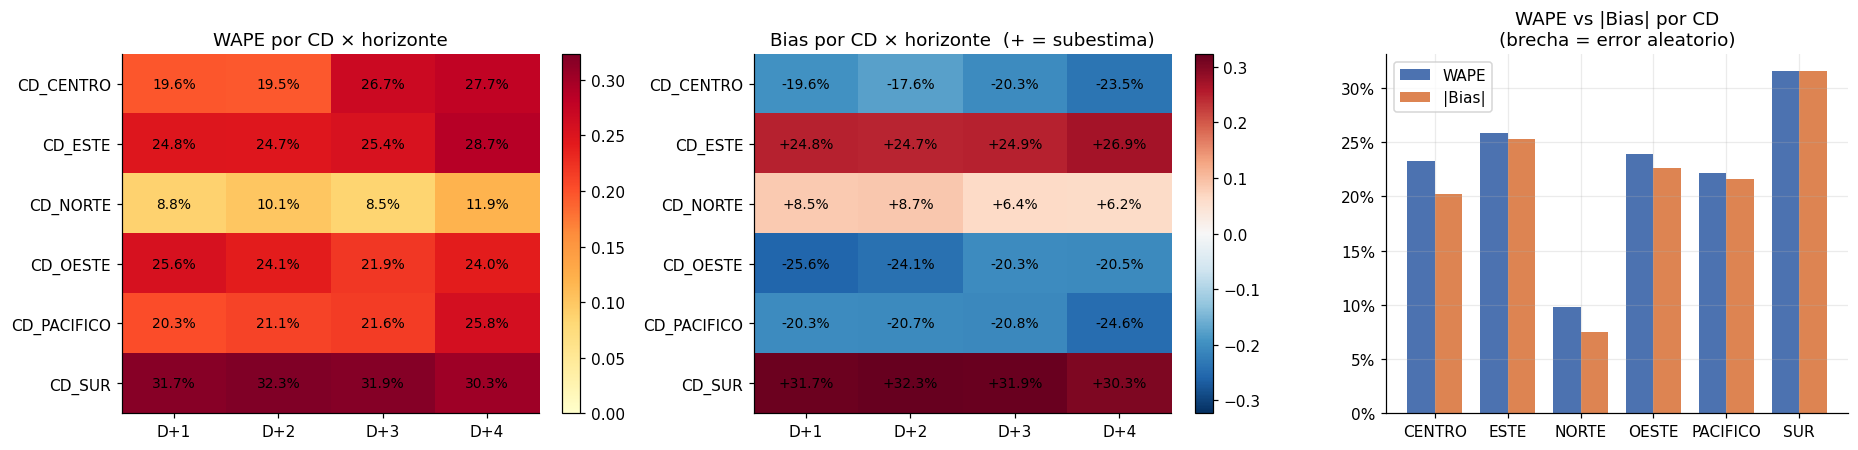

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for ax, metric, cmap in zip(axes[:2], ["WAPE", "Bias"], ["YlOrRd", "RdBu_r"]):
    piv = m_cdh[metric].unstack("horizonte")[HORIZONS].loc[CDS]
    vmax = piv.abs().max().max()
    im = ax.imshow(piv.values, cmap=cmap, vmin=0 if metric == "WAPE" else -vmax, vmax=vmax, aspect="auto")
    ax.set_xticks(range(4), HORIZONS); ax.set_yticks(range(len(CDS)), CDS); ax.grid(False)
    for i in range(piv.shape[0]):
        for j in range(piv.shape[1]):
            ax.text(j, i, f"{piv.values[i, j]:+.1%}" if metric == "Bias" else f"{piv.values[i, j]:.1%}",
                    ha="center", va="center", fontsize=9)
    ax.set_title(f"{metric} por CD × horizonte" + ("  (+ = subestima)" if metric == "Bias" else ""))
    plt.colorbar(im, ax=ax, fraction=0.046)
ax = axes[2]
x = np.arange(len(CDS)); w = 0.38
mm = m_cd.loc[CDS]
ax.bar(x - w/2, mm.WAPE, w, label="WAPE", color="#4C72B0")
ax.bar(x + w/2, mm.Bias.abs(), w, label="|Bias|", color="#DD8452")
ax.set_xticks(x, [c.replace("CD_", "") for c in CDS]); ax.set_title("WAPE vs |Bias| por CD\n(brecha = error aleatorio)")
ax.legend(); ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
plt.tight_layout(); plt.show()

In [7]:
# Respuestas explícitas de la Tarea 1 (generadas desde los datos)
sign_ok = (np.sign(m_cdh.Bias).groupby("centro_distribucion").nunique() == 1)
sub = m_cd[m_cd.Bias > 0].sort_values("Bias", ascending=False)
sob = m_cd[m_cd.Bias < 0].sort_values("Bias")
print("1) ¿Qué centros subestiman / sobreestiman?")
print("   SUBESTIMAN (Bias>0):", ", ".join(f"{c} ({b:+.1%})" for c, b in sub.Bias.items()))
print("   SOBREESTIMAN (Bias<0):", ", ".join(f"{c} ({b:+.1%})" for c, b in sob.Bias.items()))
print("   Signo idéntico en los 4 horizontes para:", sign_ok[sign_ok].index.tolist())
print(f"\n   Fracción del WAPE explicada por sesgo (|Bias|/WAPE): "
      + ", ".join(f"{c.replace('CD_','')}={r:.0%}" for c, r in (m_cd.Bias.abs() / m_cd.WAPE).items()))
print("\n2) Degradación de WAPE por horizonte:")
w = m_h.WAPE
for a, b in zip(HORIZONS[:-1], HORIZONS[1:]):
    print(f"   {a} → {b}: {w[a]:.2%} → {w[b]:.2%}  ({(w[b]-w[a])*100:+.2f} pp)")
print(f"   D+1 → D+4: {w['D+1']:.2%} → {w['D+4']:.2%}  (+{(w['D+4']/w['D+1']-1):.0%} relativo)")
dw = m_cdh.WAPE.unstack("horizonte")
print("   CDs donde D+4 es peor que D+1:", ", ".join(c for c in CDS if dw.loc[c, 'D+4'] > dw.loc[c, 'D+1']))

1) ¿Qué centros subestiman / sobreestiman?
   SUBESTIMAN (Bias>0): CD_SUR (+31.6%), CD_ESTE (+25.3%), CD_NORTE (+7.5%)
   SOBREESTIMAN (Bias<0): CD_OESTE (-22.7%), CD_PACIFICO (-21.6%), CD_CENTRO (-20.2%)
   Signo idéntico en los 4 horizontes para: ['CD_CENTRO', 'CD_ESTE', 'CD_NORTE', 'CD_OESTE', 'CD_PACIFICO', 'CD_SUR']

   Fracción del WAPE explicada por sesgo (|Bias|/WAPE): CENTRO=87%, ESTE=98%, NORTE=76%, OESTE=95%, PACIFICO=97%, SUR=100%

2) Degradación de WAPE por horizonte:
   D+1 → D+2: 19.77% → 20.30%  (+0.53 pp)
   D+2 → D+3: 20.30% → 20.85%  (+0.55 pp)
   D+3 → D+4: 20.85% → 22.53%  (+1.68 pp)
   D+1 → D+4: 19.77% → 22.53%  (+14% relativo)
   CDs donde D+4 es peor que D+1: CD_CENTRO, CD_ESTE, CD_NORTE, CD_PACIFICO


### Hallazgos de la Tarea 1

**1. El error es esencialmente un sesgo de nivel, estable por CD y no ruido.**
- **Subestiman** (el CD recibe más de lo pronosticado → riesgo de flete de emergencia): **CD_SUR (+31.6%)**, **CD_ESTE (+25.3%)** y, levemente, **CD_NORTE (+7.5%)**.
- **Sobreestiman** (flota/capacidad ociosa): **CD_OESTE (−22.7%)**, **CD_PACIFICO (−21.6%)** y **CD_CENTRO (−20.2%)**.
- El signo se mantiene en los 4 horizontes en los 6 CDs. En CD_SUR `WAPE = Bias` exactamente: **el pronóstico quedó por debajo de la demanda real todos los días**; casi todo el error de CD_ESTE, CD_PACIFICO, CD_OESTE y CD_CENTRO también es sesgo.
- CD_NORTE es el único razonablemente calibrado (WAPE ≈ 10%), y además el de mayor volumen.

**2. Degradación con el horizonte: real pero moderada y no lineal.** El WAPE global pasa de ~19.8% (D+1) a ~22.5% (D+4), +14% relativo: casi plano entre D+1 y D+3 y se rompe en D+4. Es decir, **el problema dominante no es la anticipación sino el sesgo de calibración por CD**, que es corregible con datos propios.

> Implicación: el potencial de mejora está en *recalibrar* por CD (nivel) y en capturar patrones de día de semana / picos; un modelo complejo no es lo primero que hace falta.

---
## 2. Tarea 2 — Estado del plan de entrega

In [8]:
pl = plan.copy()
pl["dow_plan"] = pl.fecha_plan.dt.dayofweek
pl["dow_real"] = pl.fecha_compra_real.dt.dayofweek
pl["delta_dias"] = (pl.fecha_compra_real - pl.fecha_plan).dt.days
pl["delta_uni"] = pl.unidades_reales - pl.unidades_plan
pl["log_ratio"] = np.log(pl.unidades_reales / pl.unidades_plan)

# --- 2.1 Bias del plan (volumen y fecha) ---
bias_vol = pl.delta_uni.sum() / pl.unidades_reales.sum()
t_stat, p_t = stats.ttest_1samp(pl.log_ratio, 0.0)
n_pos = int((pl.delta_uni > 0).sum())
p_sign = stats.binomtest(n_pos, len(pl), 0.5).pvalue
ci = stats.t.interval(0.95, len(pl) - 1, loc=pl.log_ratio.mean(), scale=stats.sem(pl.log_ratio))
print("2.1 BIAS DE VOLUMEN DEL PLAN")
print(f"   Σ plan = {pl.unidades_plan.sum():,.0f}   Σ real = {pl.unidades_reales.sum():,.0f}")
print(f"   Bias (Σ(real−plan)/Σreal) = {bias_vol:+.2%}  → el plan SUBESTIMA el volumen real")
print(f"   Compras con real > plan: {n_pos}/{len(pl)} ({n_pos/len(pl):.1%});  test de signos p = {p_sign:.2e}")
print(f"   Log-ratio medio = {pl.log_ratio.mean():+.3f} (IC95% {ci[0]:+.3f}, {ci[1]:+.3f}) → factor real/plan ≈ {math.exp(pl.log_ratio.mean()):.3f};  t-test p = {p_t:.2e}")

pl["oop"] = pl.fuera_de_plan


def by_group(col: str) -> pd.DataFrame:
    """Bias de volumen del plan (Σ(real−plan)/Σreal) y % fuera de plan por grupo."""
    g = pl.groupby(col).agg(unid_plan=("unidades_plan", "sum"), unid_real=("unidades_reales", "sum"),
                            delta=("delta_uni", "sum"), pct_fuera_plan=("oop", "mean"), n=("oop", "size"))
    g["Bias_vol"] = g.delta / g.unid_real
    return g.drop(columns="delta")
print("\n   Bias de volumen según cumplimiento de fecha:")
display(by_group("fuera_de_plan"))
print("   Bias de volumen por CD:"); display(by_group("centro_distribucion"))
print("   Bias de volumen por canal:"); display(by_group("canal_venta"))

2.1 BIAS DE VOLUMEN DEL PLAN
   Σ plan = 70,550   Σ real = 78,930
   Bias (Σ(real−plan)/Σreal) = +10.62%  → el plan SUBESTIMA el volumen real
   Compras con real > plan: 526/739 (71.2%);  test de signos p = 2.08e-31
   Log-ratio medio = +0.103 (IC95% +0.090, +0.115) → factor real/plan ≈ 1.108;  t-test p = 1.03e-51

   Bias de volumen según cumplimiento de fecha:


,unid_plan,unid_real,pct_fuera_plan,n,Bias_vol
fuera_de_plan,,,,,
0,"56,691.1800","62,259.2700",0.0000,610,0.0894
1,"13,858.7200","16,671.1500",1.0000,129,0.1687


   Bias de volumen por CD:


,unid_plan,unid_real,pct_fuera_plan,n,Bias_vol
centro_distribucion,,,,,
CD_CENTRO,"13,059.5700","14,229.0500",0.1111,126,0.0822
CD_ESTE,"5,883.3000","6,849.2000",0.1949,118,0.1410
CD_NORTE,"23,874.3100","26,827.1700",0.2439,123,0.1101
CD_OESTE,"4,527.4800","4,986.4600",0.1016,128,0.0920
CD_PACIFICO,"5,100.6400","5,851.7700",0.2131,122,0.1284
CD_SUR,"18,104.6000","20,186.7700",0.1885,122,0.1031


   Bias de volumen por canal:


,unid_plan,unid_real,pct_fuera_plan,n,Bias_vol
canal_venta,,,,,
AGENTE_COMERCIAL,"14,373.0200","15,956.9000",0.1676,173,0.0993
ATENCION_TELEFONICA,"10,594.3800","11,881.5500",0.1603,131,0.1083
PORTAL_WEB,"45,582.5000","51,091.9700",0.1816,435,0.1078


In [9]:
# --- 2.1b Bias de fecha ---
oop = pl[pl.fuera_de_plan == 1]
print("2.1b BIAS DE FECHA (solo compras fuera de plan)")
print(f"   Desfase medio = {oop.delta_dias.mean():+.2f} días;  mediana = {oop.delta_dias.median():+.0f};  "
      f"|desfase| medio = {oop.delta_dias.abs().mean():.2f}")
print(f"   Compras ATRASADAS (real > plan): {(oop.delta_dias > 0).sum()} ({(oop.delta_dias > 0).mean():.1%});  "
      f"ADELANTADAS: {(oop.delta_dias < 0).sum()} ({(oop.delta_dias < 0).mean():.1%})")
print(f"   Desfase ≤ 3 días (absoluto): {(oop.delta_dias.abs() <= 3).mean():.1%} de las compras fuera de plan")
p_date = stats.binomtest(int((oop.delta_dias > 0).sum()), len(oop), 0.5).pvalue
print(f"   Test de signos del desfase: p = {p_date:.2e}")

# --- 2.2 % fuera de plan ---
tot = pl.fuera_de_plan.mean()
print(f"\n2.2 COMPRAS FUERA DE PLAN: {tot:.1%} ({int(pl.fuera_de_plan.sum())}/{len(pl)}) del total de transacciones")
print(f"    En unidades: {oop.unidades_reales.sum() / pl.unidades_reales.sum():.1%} del volumen real")
oop_cd = pl.groupby("centro_distribucion").agg(pct_fuera=("fuera_de_plan", "mean"), n=("fuera_de_plan", "size"),
                                              desfase_medio=("delta_dias", lambda s: s[s != 0].mean())).sort_values("pct_fuera", ascending=False)
oop_dow = pl.groupby("dow_plan").agg(pct_fuera=("fuera_de_plan", "mean"), n=("fuera_de_plan", "size"),
                                     unid_plan=("unidades_plan", "sum"))
oop_dow.index = [DOW_ES[i] for i in oop_dow.index]
display(oop_cd); display(oop_dow)

# significancia: ¿difieren los CD / DOW entre sí? (chi-cuadrado)
for name, col in [("CD", "centro_distribucion"), ("día planificado", "dow_plan")]:
    chi = stats.chi2_contingency(pd.crosstab(pl[col], pl.fuera_de_plan))
    print(f"   Chi² {name}: p = {chi.pvalue:.3f}  ({'diferencias significativas' if chi.pvalue < 0.05 else 'no concluyente con esta muestra'})")

2.1b BIAS DE FECHA (solo compras fuera de plan)
   Desfase medio = +2.54 días;  mediana = +2;  |desfase| medio = 3.41
   Compras ATRASADAS (real > plan): 100 (77.5%);  ADELANTADAS: 29 (22.5%)
   Desfase ≤ 3 días (absoluto): 58.9% de las compras fuera de plan
   Test de signos del desfase: p = 2.47e-10

2.2 COMPRAS FUERA DE PLAN: 17.5% (129/739) del total de transacciones
    En unidades: 21.1% del volumen real


,pct_fuera,n,desfase_medio
centro_distribucion,,,
CD_NORTE,0.2439,123,2.5667
CD_PACIFICO,0.2131,122,2.9615
CD_ESTE,0.1949,118,2.4783
CD_SUR,0.1885,122,2.2609
CD_CENTRO,0.1111,126,2.8571
CD_OESTE,0.1016,128,1.9231


,pct_fuera,n,unid_plan
Lun,0.2212,104,"9,406.6700"
Mar,0.1622,259,"23,288.4300"
Mié,0.2294,109,"13,730.3400"
Jue,0.1391,151,"10,889.2500"
Vie,0.1552,116,"13,235.2100"


   Chi² CD: p = 0.015  (diferencias significativas)
   Chi² día planificado: p = 0.220  (no concluyente con esta muestra)


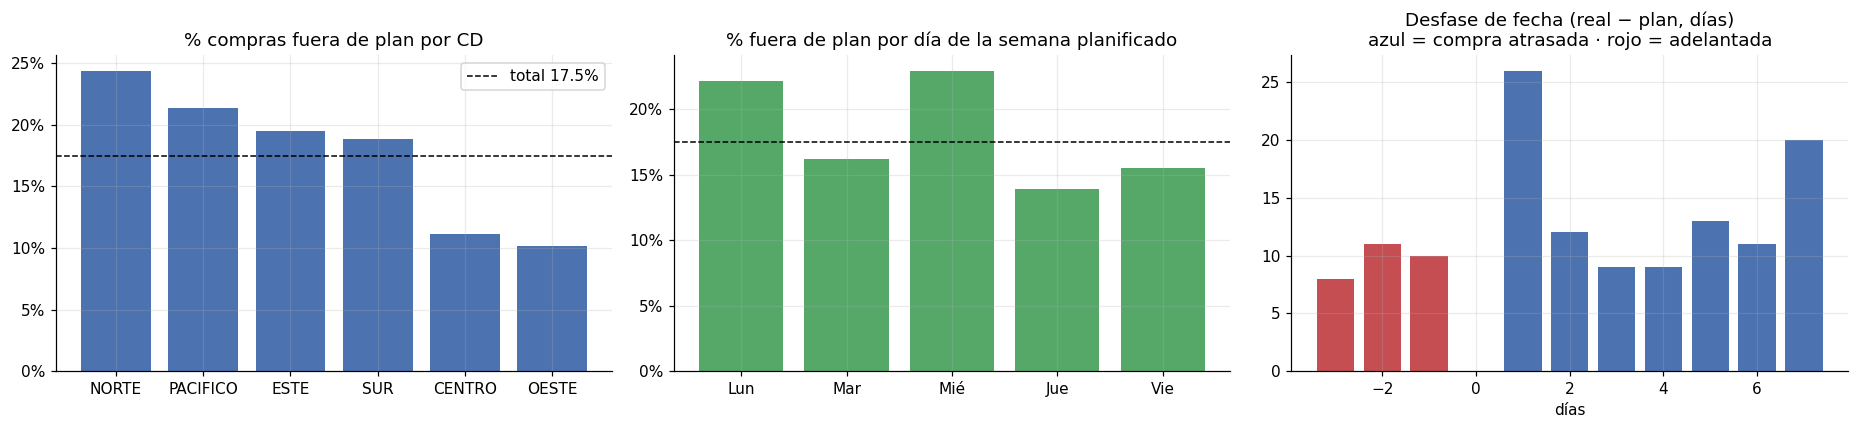

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].bar(oop_cd.index.str.replace("CD_", ""), oop_cd.pct_fuera, color="#4C72B0")
axes[0].axhline(tot, color="k", ls="--", lw=1, label=f"total {tot:.1%}"); axes[0].legend()
axes[0].set_title("% compras fuera de plan por CD"); axes[0].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
axes[1].bar(oop_dow.index, oop_dow.pct_fuera, color="#55A868")
axes[1].axhline(tot, color="k", ls="--", lw=1)
axes[1].set_title("% fuera de plan por día de la semana planificado"); axes[1].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
vc = oop.delta_dias.value_counts().sort_index()
axes[2].bar(vc.index, vc.values, color=["#C44E52" if d < 0 else "#4C72B0" for d in vc.index])
axes[2].set_title("Desfase de fecha (real − plan, días)\nazul = compra atrasada · rojo = adelantada")
axes[2].set_xlabel("días"); plt.tight_layout(); plt.show()

### 2.1–2.2 Respuestas

- **Sí existe bias, y es de subestimación en volumen**: el plan compromete ~10.6% menos unidades que las realmente compradas (Σplan = 70.5k vs Σreal = 78.9k; en 71% de las compras el cliente compró más de lo planificado; el factor real/plan ≈ 1.11, estadísticamente significativo). El sesgo **no se explica solo por desfase de fechas**: incluso las compras *en la fecha pactada* superan el plan en ~9% (Bias +8.9%), y las compras fuera de plan en ~17% (Bias +16.9%). Es además **homogéneo**: entre +8% y +14% en los 6 CDs y en los 3 canales.
- **Sesgo de fecha**: cuando el cliente se desvía lo hace principalmente **hacia adelante** (77.5% de los desvíos son compras posteriores a la fecha planificada; desfase medio ≈ +2.5 días; ~59% de los desvíos caen dentro de ±3 días). El plan es, por tanto, optimista en timing y pesimista en volumen.
- **% fuera de plan**: **17.5%** de las transacciones (21% del volumen, porque los desvíos son además de mayor tamaño). Por CD varía entre ~10% (CD_OESTE, CD_CENTRO) y ~24% (CD_NORTE, el de mayor volumen → mayor impacto operativo); la diferencia entre CDs es estadísticamente significativa (χ² p ≈ 0.015). Por día planificado, lunes y miércoles son los menos fieles (~22–23%) y martes/jueves/viernes los más estables (~14–16%), **pero esta diferencia no es significativa con 739 observaciones** (χ² p ≈ 0.22): se reporta como indicio, no como hecho.

### 2.3 Métricas adicionales (calculadas abajo)

Resultados clave: adhesión media por cliente de 82% (31 de 90 clientes con 100%, 20 de 90 bajo 70%); **el 10% de los clientes explica 48% de las unidades fuera de plan** (Gini 0.68); y el martes pasa de 33% del volumen *planificado* a 46% del *real* (+13 pp), alimentado por compras que migran desde lunes, miércoles, jueves y viernes.

| Métrica | Por qué aporta |
|---|---|
| **Adhesión por cliente** (% de entregas en la fecha pactada) | Distingue ruido uniforme de un grupo pequeño de clientes crónicamente inestables; permite acciones dirigidas. |
| **Variación de fecha** (media, mediana, |Δ|, distribución) | Mide la *flexibilidad real* del cliente: define qué ventana de re-agendamiento es aceptable. |
| **Variación de volumen** (real/plan por cliente, y MAPE de volumen) | Separa error de *cantidad* de error de *fecha*; alimenta una corrección de volumen por cliente/canal. |
| **Concentración de desvíos** (curva Pareto / Gini sobre unidades fuera de plan) | Si pocos clientes generan la mayoría del desvío, basta con gestionar a esos clientes. |
| **Migración de día** (matriz día planificado → día real) | Muestra hacia qué días se "escapa" la demanda (p. ej. hacia el martes) y cuantifica el pico real vs planificado. |
| **Carga vs capacidad** (utilización diaria por CD) | Conecta el comportamiento del cliente con el costo: días sobre ~90–100% de capacidad son los que disparan fletes de emergencia. |

In [11]:
# --- 2.3 Métricas adicionales ---
cli = pl.groupby(["cliente_id", "centro_distribucion"]).agg(
    entregas=("fuera_de_plan", "size"),
    adhesion=("fuera_de_plan", lambda s: 1 - s.mean()),
    desfase_medio_abs=("delta_dias", lambda s: s.abs().mean()),
    ratio_vol=("unidades_reales", "sum"),
    plan_vol=("unidades_plan", "sum"),
    unid_fuera=("unidades_reales", lambda s: s[pl.loc[s.index, "fuera_de_plan"] == 1].sum()),
).reset_index()
cli["ratio_vol"] = cli.ratio_vol / cli.plan_vol

print("Adhesión por cliente (1 − %fuera de plan):")
print(cli.adhesion.describe().round(3).to_string())
print(f"\nClientes con adhesión = 100%: {(cli.adhesion == 1).sum()}/90;   adhesión < 70%: {(cli.adhesion < 0.7).sum()}/90")

# Pareto / Gini de unidades fuera de plan
srt = cli.sort_values("unid_fuera", ascending=False)
cum = srt.unid_fuera.cumsum() / srt.unid_fuera.sum()
top10 = cum.iloc[8]; top20 = cum.iloc[17]
x = np.sort(cli.unid_fuera.values); n = len(x)
gini = (2 * np.sum((np.arange(1, n + 1)) * x) / (n * x.sum())) - (n + 1) / n
print(f"Concentración de desvíos: top 10% clientes (9) = {top10:.0%} de las unidades fuera de plan; top 20% = {top20:.0%};  Gini = {gini:.2f}")

# Matriz de migración de día (filas = planificado, columnas = real)
mig = pd.crosstab(pl.dow_plan.map(dict(enumerate(DOW_ES))), pl.dow_real.map(dict(enumerate(DOW_ES))))
mig = mig.reindex(index=DOW_ES[:5], columns=DOW_ES).fillna(0).astype(int)
print("\nMatriz de migración (filas: día planificado → columnas: día real):"); display(mig)

share_plan = pl.groupby("dow_plan").unidades_plan.sum() / pl.unidades_plan.sum()
share_real = pl.groupby("dow_real").unidades_reales.sum() / pl.unidades_reales.sum()
cmp_dow = pd.DataFrame({"%unid_plan": share_plan, "%unid_real": share_real}).reindex(range(7)).fillna(0)
cmp_dow.index = DOW_ES
cmp_dow["Δ pp"] = (cmp_dow["%unid_real"] - cmp_dow["%unid_plan"]) * 100
display(cmp_dow)
print(f"Compras reales en fin de semana (no planificado): {(pl.dow_real >= 5).sum()} ({(pl.dow_real >= 5).mean():.1%})")

Adhesión por cliente (1 − %fuera de plan):
count   90.0000
mean     0.8240
std      0.1780
min      0.3330
25%      0.7140
50%      0.8750
75%      1.0000
max      1.0000

Clientes con adhesión = 100%: 31/90;   adhesión < 70%: 20/90
Concentración de desvíos: top 10% clientes (9) = 48% de las unidades fuera de plan; top 20% = 68%;  Gini = 0.68

Matriz de migración (filas: día planificado → columnas: día real):


dow_real,Lun,Mar,Mié,Jue,Vie,Sáb,Dom
dow_plan,,,,,,,
Lun,81,16,3,1,1,1,1
Mar,3,237,7,2,1,4,5
Mié,1,16,84,2,2,3,1
Jue,1,15,1,130,1,1,2
Vie,2,10,2,0,98,0,4


,%unid_plan,%unid_real,Δ pp
Lun,0.1333,0.0965,-3.6821
Mar,0.3301,0.4620,13.1925
Mié,0.1946,0.1379,-5.6714
Jue,0.1543,0.1279,-2.6486
Vie,0.1876,0.1406,-4.7021
Sáb,0.0000,0.0091,0.9099
Dom,0.0000,0.0260,2.6019


Compras reales en fin de semana (no planificado): 22 (3.0%)


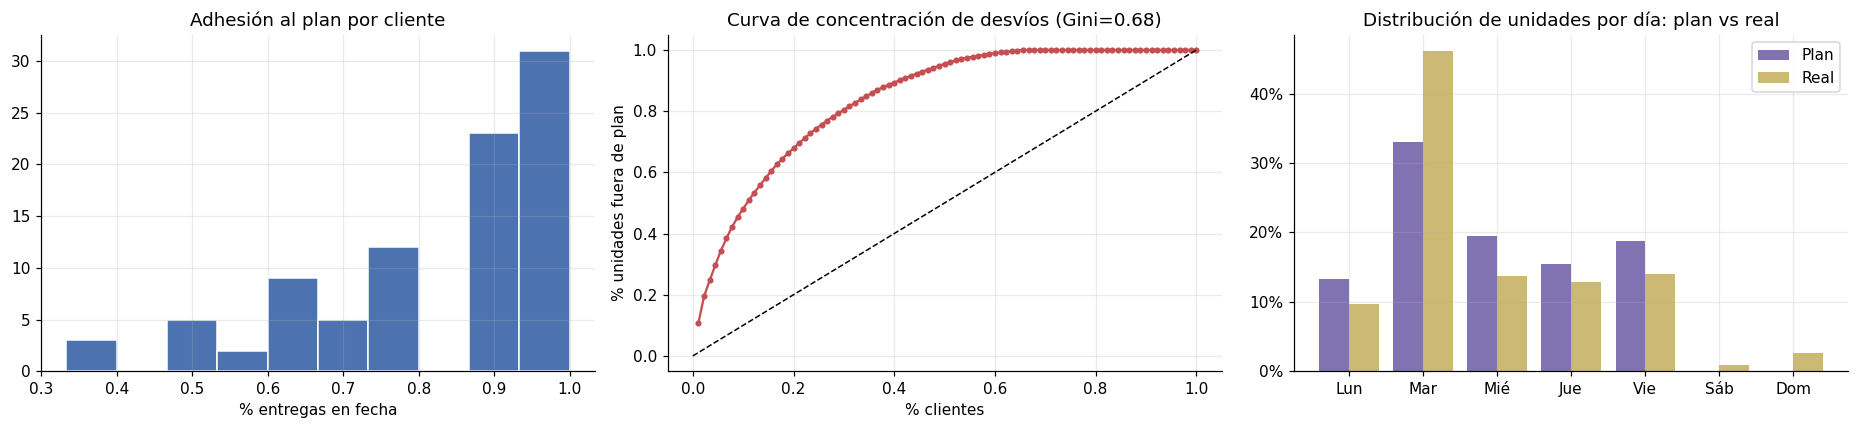

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].hist(cli.adhesion, bins=10, color="#4C72B0", edgecolor="w")
axes[0].set_title("Adhesión al plan por cliente"); axes[0].set_xlabel("% entregas en fecha")
axes[1].plot(np.arange(1, 91) / 90, cum.values, marker=".", color="#C44E52"); axes[1].plot([0, 1], [0, 1], "k--", lw=1)
axes[1].set_title(f"Curva de concentración de desvíos (Gini={gini:.2f})"); axes[1].set_xlabel("% clientes"); axes[1].set_ylabel("% unidades fuera de plan")
xx = np.arange(7)
axes[2].bar(xx - 0.2, cmp_dow["%unid_plan"], 0.4, label="Plan", color="#8172B2")
axes[2].bar(xx + 0.2, cmp_dow["%unid_real"], 0.4, label="Real", color="#CCB974")
axes[2].set_xticks(xx, DOW_ES); axes[2].legend(); axes[2].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
axes[2].set_title("Distribución de unidades por día: plan vs real")
plt.tight_layout(); plt.show()

### 2.4 Estrategia para aplanar la curva de demanda (pico de los martes)

**Diagnóstico.** En el plan de clientes, los martes pasan de 33% de las unidades planificadas a 46% de las reales: los clientes que se desvían *convergen* hacia el martes (ver matriz de migración). A nivel CD, el martes es el día de mayor demanda en unidades en los 6 centros (+18% a +33% sobre el promedio diario, tabla siguiente).

**Mecanismo propuesto: "fecha dinámica con incentivo" (peak-shaving en el momento del pedido).**
1. Al cotizar el pedido, el motor calcula para cada fecha candidata dentro de la **ventana de flexibilidad del cliente** (±1–3 días; observado: ~59% de los desvíos reales caben en ±3 días y 76% en ±5) la *utilización proyectada* = (pronóstico corregido + pedidos ya comprometidos) / capacidad del CD.
2. Se **recomienda por defecto la fecha de menor utilización** y se muestra la del martes como opción "estándar". Para fechas valle se ofrece un incentivo marginal (despacho sin costo, mejor ventana horaria, prioridad de stock), financiado con el ahorro esperado de flete de emergencia.
3. Para clientes recurrentes con plan semanal, el plan se **pre-distribuye** (*nudging* del día base) usando su historial de adhesión: clientes con alta flexibilidad y baja adhesión se mueven primero (la concentración de desvíos indica que pocos clientes explican gran parte).
4. Se aplica un **tope blando de capacidad** (~90%) por CD-día: sobre ese umbral el sistema deja de ofrecer esa fecha como default.

**Implementación.** (a) Pronóstico corregido (§3) como input de carga proyectada; (b) servicio de recomendación (§5) con regla de optimización simple (greedy / MILP pequeño por CD-semana); (c) despliegue por *A/B test aleatorizado a nivel cliente o CD* con holdout para medir efecto causal; (d) monitoreo continuo.

**KPIs:** (i) **Peak-to-Average Ratio semanal** de carga por CD (objetivo ↓), (ii) **% de CD-días con utilización > 90% / > 100%**, (iii) **share de martes** sobre el volumen semanal, (iv) **tasa de aceptación** de la fecha recomendada, (v) **costo de flete de emergencia por unidad**, y como *guardrail*: nivel de servicio (OTIF) y adhesión al plan.

A continuación, una **simulación ilustrativa** sobre la demanda histórica diaria por CD: se mueve una fracción `α` (clientes receptivos) de la carga que excede el 90% de capacidad hacia el día vecino (±2 días) con mayor holgura.

In [13]:
cap_w = cap.pivot(index="fecha", columns="centro_distribucion", values="capacidad_maxima_unidades")
tue_idx = (daily[CDS].assign(dow=daily.index.dayofweek).groupby("dow").mean().loc[1] / daily[CDS].mean())
print("Demanda real de los martes / promedio diario de cada CD:")
display(tue_idx.rename("índice").to_frame().T)

Demanda real de los martes / promedio diario de cada CD:


centro_distribucion,CD_CENTRO,CD_ESTE,CD_NORTE,CD_OESTE,CD_PACIFICO,CD_SUR
índice,1.2440,1.2502,1.1785,1.2657,1.2749,1.3310


In [14]:
def flatten_simulation(daily_units: pd.DataFrame, capacity: pd.DataFrame, alpha: float,
                       trigger: float = 0.90, window: int = 2) -> pd.DataFrame:
    """Peak-shaving greedy. Mueve hasta `alpha`×unidades de un día con utilización > trigger
    hacia días vecinos (±window) con holgura bajo `trigger`. Devuelve la demanda re-distribuida."""
    out = daily_units.copy()
    for cd in out.columns:
        u = out[cd].to_numpy(dtype=float).copy()
        c = capacity[cd].reindex(out.index).to_numpy(dtype=float)
        order = np.argsort(-(u / c))
        for i in order:
            excess = u[i] - trigger * c[i]
            if excess <= 0:
                continue
            move = min(alpha * u[i], excess)
            neighbors = [j for j in range(max(0, i - window), min(len(u), i + window + 1)) if j != i]
            neighbors.sort(key=lambda j: u[j] / c[j])
            for j in neighbors:
                room = trigger * c[j] - u[j]
                if room <= 0 or move <= 0:
                    continue
                q = min(room, move)
                u[i] -= q; u[j] += q; move -= q
        out[cd] = u
    return out


def load_profile(d: pd.DataFrame, c: pd.DataFrame) -> dict[str, float]:
    util = d / c
    wk = d.groupby(d.index.to_period("W")).transform("max") / d.groupby(d.index.to_period("W")).transform("mean")
    return {"%CD-días util>90%": float((util > 0.9).to_numpy().mean()),
            "%CD-días util>100%": float((util > 1.0).to_numpy().mean()),
            "PAR semanal medio (máx/prom)": float(wk.to_numpy().mean()),
            "CV de utilización": float(util.stack().std() / util.stack().mean()),
            "martes: % del volumen semanal": float(d[d.index.dayofweek == 1].sum().sum() / d.sum().sum())}


sim = pd.DataFrame({f"α={a:.0%}": load_profile(flatten_simulation(daily[CDS], cap_w[CDS], a), cap_w[CDS])
                    for a in [0.0, 0.1, 0.2, 0.3, 0.5]}).T
print("Efecto simulado del peak-shaving (α = fracción de carga excedente que acepta moverse):")
display(sim)
print("Nota: simulación sobre demanda real; no modela elasticidad ni costo del incentivo. α=0% es la línea base.")
print("Lectura: mover solo el 10% de la carga excedente baja los CD-días con utilización >90% de 18% a ~4% y elimina los >100% (3.6% → 0%); "
      "el PAR semanal cae poco (1.27 → 1.23) y la participación del martes casi no cambia: el beneficio principal es "
      "evitar exceder la capacidad, no aplanar toda la curva.")

Efecto simulado del peak-shaving (α = fracción de carga excedente que acepta moverse):


,%CD-días util>90%,%CD-días util>100%,PAR semanal medio (máx/prom),CV de utilización,martes: % del volumen semanal
α=0%,0.1806,0.0361,1.2689,0.1195,0.1663
α=10%,0.0361,0.0000,1.2349,0.0943,0.1652
α=20%,0.0028,0.0000,1.2307,0.0925,0.1649
α=30%,0.0028,0.0000,1.2307,0.0925,0.1649
α=50%,0.0028,0.0000,1.2307,0.0925,0.1649


Nota: simulación sobre demanda real; no modela elasticidad ni costo del incentivo. α=0% es la línea base.
Lectura: mover solo el 10% de la carga excedente baja los CD-días con utilización >90% de 18% a ~4% y elimina los >100% (3.6% → 0%); el PAR semanal cae poco (1.27 → 1.23) y la participación del martes casi no cambia: el beneficio principal es evitar exceder la capacidad, no aplanar toda la curva.


---
## 3. Tarea 3 — Modelo complementario de forecast (corrección del pronóstico base)

### Diseño
- **Target:** `y = log(real / pronóstico_base)`. Modelar el *ratio* (en logs) en vez del nivel (i) hace la corrección multiplicativa y comparable entre CDs de distinto tamaño, (ii) preserva la señal del modelo base en lugar de reemplazarla y (iii) es robusto con poca historia (60 días).
- **Pronóstico corregido:** `fc_corr = fc_base · exp(ŷ)`, con *guardrail* de ratio ∈ [0.5, 2.0].
- **Prevención de fuga temporal (crítico):** para un pronóstico emitido el día *e* solo se usan actuales con `fecha_despacho ≤ e−1`. Para entrenar en un origen *E₀* solo se usan filas cuyo `fecha_despacho < E₀` (el target ya se conoce). Hay un test automático de no-leakage más abajo.
- **Features (todas conocidas en el momento de emisión):**

| Familia | Features |
|---|---|
| Base | `log(fc)`, horizonte `h`, CD (one-hot) |
| Calendario / picos | día de semana, `es_martes` (pico documentado en Tarea 2), `fin_de_semana`, `spike_lag7` (¿la misma fecha de hace 7 días estuvo >15% sobre su media de 14 días?), `fc_util` = fc / capacidad (anticipa días pico respecto del límite operativo) |
| Rolling | media móvil 7/14 días de actuales, desv. estándar móvil 7d, `fc / media7`, `lag7 / media14` |
| Error reciente | ratio real/pronóstico móvil 7/14 días *para el mismo CD y horizonte* (cuánto se ha equivocado el modelo base últimamente) |
- **Modelos:** (a) *Recalibración por CD* (baseline simple: ratio histórico acumulado Σreal/Σfc por CD), (b) **Ridge** (modelo propuesto: interpretable, estable con ~10³ filas), (c) **HistGradientBoosting** (challenger no lineal). LightGBM es intercambiable con (c); se usa `scikit-learn` para no añadir dependencias.

In [15]:
FEATURES_NUM = ["lfc", "h", "es_martes", "es_finde", "spike_lag7", "fc_util",
                "rm7", "rm14", "rstd7", "fc_vs_rm7", "lag7_vs_rm14", "rr7", "rr14"]
FEATURES_CAT = ["centro_distribucion"]
PEAK_MULT = 1.15


def build_features(fc_rows: pd.DataFrame, daily_actuals: pd.DataFrame, capacity: pd.DataFrame) -> pd.DataFrame:
    """Ingeniería de features leakage-safe.

    Para una fila con emisión `e` y objetivo `t = e + h`, solo usa `daily_actuals` en fechas ≤ e−1.
    `daily_actuals` es (fecha × CD) y puede ser una vista truncada (producción: sin datos futuros).
    """
    assert fc_rows.h.max() <= 6, "lag7 requiere horizonte ≤ 6 para no mirar el futuro"
    rows = []
    for cd, g in fc_rows.groupby("centro_distribucion"):
        a = daily_actuals[cd].astype(float)
        full_idx = pd.date_range(a.index.min(), max(a.index.max(), g.fecha_despacho.max()), freq="D")
        a = a.reindex(full_idx)
        known7 = a.rolling(7, min_periods=3).mean().shift(1)     # valor en e usa ≤ e−1
        known14 = a.rolling(14, min_periods=7).mean().shift(1)
        std7 = a.rolling(7, min_periods=5).std().shift(1)
        lag7 = a.shift(7)                                         # valor en t usa t−7 ≤ e−1 si h ≤ 6
        # media de 14d conocida *en la fecha del lag7* (para medir si esa fecha fue un pico)
        known14_at_lag = a.rolling(14, min_periods=7).mean().shift(8)
        # ratio real/fc por horizonte, indexado por fecha objetivo
        gg = g.copy()
        cd_cap = capacity[cd]
        e = gg.fecha_emision
        t = gg.fecha_despacho
        gg["rm7"] = e.map(known7)
        gg["rm14"] = e.map(known14)
        gg["rstd7"] = e.map(std7)
        gg["lag7"] = t.map(lag7)
        gg["lag7_base"] = t.map(known14_at_lag)
        gg["capacidad"] = t.map(cd_cap)
        rows.append(gg)
    f = pd.concat(rows).sort_values(["centro_distribucion", "h", "fecha_despacho"])

    # ratio real/fc móvil por (CD, h): ventana sobre fechas objetivo, desplazada h+1 (conocido hasta e−1)
    f["_ratio"] = f["real"] / f["fc"]
    for w in (7, 14):
        f[f"rr{w}"] = np.nan
    for (cd, h), g in f.groupby(["centro_distribucion", "h"]):
        s = g.set_index("fecha_despacho")["_ratio"]
        s = s.reindex(pd.date_range(s.index.min(), s.index.max(), freq="D"))
        for w in (7, 14):
            r = s.rolling(w, min_periods=3).mean().shift(int(h) + 1)
            f.loc[g.index, f"rr{w}"] = g.fecha_despacho.map(r).to_numpy()

    f["dow"] = f.fecha_despacho.dt.dayofweek
    f["es_martes"] = (f.dow == 1).astype(float)
    f["es_finde"] = (f.dow >= 5).astype(float)
    f["lfc"] = np.log(f["fc"])
    f["fc_util"] = f["fc"] / f["capacidad"]
    f["fc_vs_rm7"] = f["fc"] / f["rm7"]
    f["lag7_vs_rm14"] = f["lag7"] / f["rm14"]
    f["spike_lag7"] = np.where(f["lag7"].notna() & f["lag7_base"].notna(),
                               (f["lag7"] > PEAK_MULT * f["lag7_base"]).astype(float), np.nan)
    f["y"] = np.log(f["real"] / f["fc"])
    return f.drop(columns=["_ratio", "lag7_base"]).sort_values(["fecha_emision", "centro_distribucion", "h"]).reset_index(drop=True)


feat = build_features(fc, daily, cap_w)
print(feat.shape)
print("% NaN por feature:"); print(feat[FEATURES_NUM].isna().mean().round(3).to_string())

# --- test de no-leakage: recomputar con la historia truncada a e−1 debe dar los mismos features ---
rng = np.random.default_rng(SEED)
check_cols = ["rm7", "rm14", "rstd7", "lag7", "rr7", "rr14", "spike_lag7"]
sample = feat.iloc[rng.choice(len(feat), 25, replace=False)]
n_bad = 0
for _, r in sample.iterrows():
    cutoff = r.fecha_emision - pd.Timedelta(days=1)
    trunc = daily[daily.index <= cutoff]
    # para el cálculo de rr*, el real de targets >= e no debe existir
    sub = fc[(fc.centro_distribucion == r.centro_distribucion)].copy()
    sub.loc[sub.fecha_despacho > cutoff, "real"] = np.nan
    ff = build_features(sub, trunc, cap_w)
    q = ff[(ff.fecha_emision == r.fecha_emision) & (ff.h == r.h)].iloc[0]
    for c in check_cols:
        a, b = r[c], q[c]
        if not ((pd.isna(a) and pd.isna(b)) or np.isclose(a, b, equal_nan=True)):
            n_bad += 1
print(f"\nTest de no-leakage sobre 25 filas × {len(check_cols)} features → discrepancias: {n_bad}")
assert n_bad == 0, "Fuga temporal detectada"

(1380, 23)
% NaN por feature:
lfc            0.0000
h              0.0000
es_martes      0.0000
es_finde       0.0000
spike_lag7     0.2000
fc_util        0.0000
rm7            0.0520
rm14           0.1220
rstd7          0.0870
fc_vs_rm7      0.0520
lag7_vs_rm14   0.1220
rr7            0.0960
rr14           0.0960



Test de no-leakage sobre 25 filas × 7 features → discrepancias: 0


In [16]:
def make_ridge(alpha: float = 3.0) -> Pipeline:
    pre = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), FEATURES_NUM),
        ("cat", OneHotEncoder(handle_unknown="ignore"), FEATURES_CAT)])
    return Pipeline([("pre", pre), ("m", Ridge(alpha=alpha))])


def make_hgb() -> Pipeline:
    pre = ColumnTransformer([
        ("num", "passthrough", FEATURES_NUM),
        ("cat", OneHotEncoder(handle_unknown="ignore"), FEATURES_CAT)])
    return Pipeline([("pre", pre), ("m", HistGradientBoostingRegressor(
        max_depth=3, learning_rate=0.05, max_iter=150, min_samples_leaf=15, random_state=SEED))])


RATIO_BOUNDS = (0.5, 2.0)
MODELS: dict[str, Callable[[], Pipeline]] = {"ridge": make_ridge, "hgb": make_hgb}
ABLATIONS: dict[str, tuple[list[str], list[str]]] = {
    "ridge_solo_nivel": (["lfc", "h"], FEATURES_CAT),
    "ridge_+calendario": (["lfc", "h", "es_martes", "es_finde", "fc_util"], FEATURES_CAT),
    "ridge_+rolling": (["lfc", "h", "es_martes", "es_finde", "fc_util", "rm7", "rm14", "rstd7", "fc_vs_rm7",
                        "lag7_vs_rm14", "spike_lag7"], FEATURES_CAT),
}


def _ridge_with(num: list[str], cat: list[str], alpha: float = 3.0) -> Pipeline:
    pre = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])
    return Pipeline([("pre", pre), ("m", Ridge(alpha=alpha))])


def rolling_origin_backtest(f: pd.DataFrame, initial_days: int = 28, step_days: int = 7,
                            t0: pd.Timestamp | None = None) -> tuple[pd.DataFrame, list[pd.DataFrame]]:
    """Backtest de origen rodante con ventana expansiva.

    Origen E0 (fecha): entrena con filas cuyo target ya ocurrió (`fecha_despacho < E0`) y predice las
    emisiones en [E0, E0+step). Se repite avanzando `step_days` hasta agotar los datos.
    """
    t0 = t0 or daily.index.min()
    emis = (f.fecha_emision - t0).dt.days
    out: list[pd.DataFrame] = []
    coefs: list[pd.DataFrame] = []
    e0, fold = initial_days, 0
    while e0 <= emis.max():
        tr = f[f.fecha_despacho < t0 + pd.Timedelta(days=e0)]
        te = f[(emis >= e0) & (emis < e0 + step_days)].copy()
        if te.empty:
            break
        te["fold"] = fold
        te["origen"] = t0 + pd.Timedelta(days=e0)
        te["n_train"] = len(tr)
        # (a) recalibración simple por CD
        ratio = tr.groupby("centro_distribucion").apply(lambda g: g.real.sum() / g.fc.sum(), include_groups=False)
        te["pred_recal_cd"] = te.fc * te.centro_distribucion.map(ratio).fillna(1.0)
        # (b)(c) modelos de corrección
        for name, factory in MODELS.items():
            mdl = factory().fit(tr[FEATURES_NUM + FEATURES_CAT], tr.y)
            yhat = mdl.predict(te[FEATURES_NUM + FEATURES_CAT])
            te[f"pred_{name}"] = te.fc * np.exp(np.clip(yhat, np.log(RATIO_BOUNDS[0]), np.log(RATIO_BOUNDS[1])))
            if name == "ridge":
                names = mdl.named_steps["pre"].get_feature_names_out()
                coefs.append(pd.DataFrame({"feature": names, "coef": mdl.named_steps["m"].coef_, "fold": fold}))
        for name, (num, cat) in ABLATIONS.items():
            mdl = _ridge_with(num, cat).fit(tr[num + cat], tr.y)
            yhat = mdl.predict(te[num + cat])
            te[f"pred_{name}"] = te.fc * np.exp(np.clip(yhat, np.log(RATIO_BOUNDS[0]), np.log(RATIO_BOUNDS[1])))
        out.append(te)
        e0 += step_days
        fold += 1
    return pd.concat(out, ignore_index=True), coefs


bt, coefs = rolling_origin_backtest(feat, initial_days=28, step_days=7)
bt["pred_base"] = bt["fc"]
print(f"Folds: {bt.fold.nunique()}   filas evaluadas: {len(bt)}   ventana de test: "
      f"{bt.fecha_emision.min().date()} → {bt.fecha_emision.max().date()}   (emisión)")
print("Entrenamiento mínimo:", int(bt.groupby('fold').n_train.first().min()), "filas;  máximo:", int(bt.groupby('fold').n_train.first().max()))

Folds: 5   filas evaluadas: 708   ventana de test: 2026-01-29 → 2026-02-28   (emisión)
Entrenamiento mínimo: 612 filas;  máximo: 1284


In [17]:
PRED_COLS = {"pred_base": "Base (sistema actual)", "pred_recal_cd": "Recalibración por CD",
             "pred_ridge": "Ridge (propuesto)", "pred_hgb": "HistGradientBoosting"}
res = pd.concat({lbl: error_metrics(bt, None, pred=col).iloc[0] for col, lbl in PRED_COLS.items()}, axis=1).T
res["mejora_WAPE_vs_base_pp"] = (res.WAPE.iloc[0] - res.WAPE) * 100
res["mejora_relativa"] = 1 - res.WAPE / res.WAPE.iloc[0]
print("WAPE GLOBAL del backtest de origen rodante (mismas filas para todos los modelos):")
display(res[["WAPE", "Bias", "mejora_WAPE_vs_base_pp", "mejora_relativa", "n"]])

abl_cols = {"pred_base": "0. Base", "pred_recal_cd": "1. Recalibración por CD", "pred_ridge_solo_nivel": "2. Ridge: nivel + horizonte + CD",
            "pred_ridge_+calendario": "3. + calendario / picos / capacidad", "pred_ridge_+rolling": "4. + rolling features",
            "pred_ridge": "5. + error reciente (Ridge completo)"}
abl = pd.Series({lbl: error_metrics(bt, None, pred=c).WAPE.iloc[0] for c, lbl in abl_cols.items()}, name="WAPE")
print("\nAblación (¿de dónde viene la mejora?):")
display(abl.to_frame().assign(delta_pp=lambda d: (d.WAPE - d.WAPE.shift(1)) * 100))

WAPE GLOBAL del backtest de origen rodante (mismas filas para todos los modelos):


,WAPE,Bias,mejora_WAPE_vs_base_pp,mejora_relativa,n
Base (sistema actual),0.2073,0.0669,0.0000,0.0000,708.0000
Recalibración por CD,0.0922,0.0003,11.5174,0.5555,708.0000
Ridge (propuesto),0.0719,0.0104,13.5405,0.6531,708.0000
HistGradientBoosting,0.0686,0.0121,13.8713,0.6691,708.0000



Ablación (¿de dónde viene la mejora?):


,WAPE,delta_pp
0. Base,0.2073,NaN
1. Recalibración por CD,0.0922,-11.5174
2. Ridge: nivel + horizonte + CD,0.0786,-1.3548
3. + calendario / picos / capacidad,0.0715,-0.7124
4. + rolling features,0.0718,0.0300
5. + error reciente (Ridge completo),0.0719,0.0143


In [18]:
# --- Desglose: por horizonte, por CD, por fold; y significancia por bootstrap de días (block bootstrap) ---
cmp_h = pd.concat({lbl: error_metrics(bt, "horizonte", pred=c).WAPE for c, lbl in PRED_COLS.items()}, axis=1)
cmp_cd = pd.concat({lbl: error_metrics(bt, "centro_distribucion", pred=c).WAPE for c, lbl in PRED_COLS.items()}, axis=1)
bias_cd = pd.concat({lbl: error_metrics(bt, "centro_distribucion", pred=c).Bias for c, lbl in PRED_COLS.items()}, axis=1)
fold_tbl = pd.DataFrame({
    "origen": bt.groupby("fold").origen.first().dt.date,
    "WAPE_base": bt.groupby("fold").apply(lambda g: error_metrics(g, None, pred="pred_base").WAPE.iloc[0], include_groups=False),
    "WAPE_ridge": bt.groupby("fold").apply(lambda g: error_metrics(g, None, pred="pred_ridge").WAPE.iloc[0], include_groups=False),
    "WAPE_hgb": bt.groupby("fold").apply(lambda g: error_metrics(g, None, pred="pred_hgb").WAPE.iloc[0], include_groups=False),
})
print("WAPE por horizonte:"); display(cmp_h)
print("WAPE por CD:"); display(cmp_cd)
print("Bias por CD:"); display(bias_cd)
print("WAPE por fold:"); display(fold_tbl)
print(f"Folds donde Ridge < Base: {(fold_tbl.WAPE_ridge < fold_tbl.WAPE_base).sum()}/{len(fold_tbl)}")

# Bootstrap por fecha de despacho (remuestrea días completos para respetar la correlación intra-día)
days = bt.fecha_despacho.unique()
by_day = bt.groupby("fecha_despacho").apply(lambda g: pd.Series({
    "den": g.real.abs().sum(), "abs_base": (g.real - g.pred_base).abs().sum(), "abs_ridge": (g.real - g.pred_ridge).abs().sum()}),
    include_groups=False)
boot = []
for _ in range(2000):
    s = by_day.iloc[rng.integers(0, len(by_day), len(by_day))]
    boot.append((s.abs_base.sum() - s.abs_ridge.sum()) / s.den.sum())
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"\nMejora de WAPE (Base − Ridge): {np.mean(boot)*100:.2f} pp  IC95% bootstrap [{lo*100:.2f}, {hi*100:.2f}] pp  "
      f"→ {'significativa' if lo > 0 else 'NO significativa'}")

WAPE por horizonte:


,Base (sistema actual),Recalibración por CD,Ridge (propuesto),HistGradientBoosting
horizonte,,,,
D+1,0.1933,0.0397,0.0579,0.0512
D+2,0.2035,0.0795,0.0639,0.0586
D+3,0.2045,0.1098,0.0726,0.0750
D+4,0.2298,0.1451,0.0952,0.0919


WAPE por CD:


,Base (sistema actual),Recalibración por CD,Ridge (propuesto),HistGradientBoosting
centro_distribucion,,,,
CD_CENTRO,0.2304,0.1254,0.0820,0.0820
CD_ESTE,0.2644,0.1609,0.0950,0.0794
CD_NORTE,0.0959,0.0754,0.0779,0.0663
CD_OESTE,0.2345,0.0864,0.0657,0.0619
CD_PACIFICO,0.2314,0.0819,0.0560,0.0571
CD_SUR,0.3114,0.0721,0.0545,0.0637


Bias por CD:


,Base (sistema actual),Recalibración por CD,Ridge (propuesto),HistGradientBoosting
centro_distribucion,,,,
CD_CENTRO,-0.1935,0.0081,0.0224,0.0106
CD_ESTE,0.2587,0.0064,0.0223,0.0321
CD_NORTE,0.0776,0.0037,0.0038,0.0021
CD_OESTE,-0.2195,0.0056,0.0115,0.0093
CD_PACIFICO,-0.2252,-0.0162,0.0126,0.0058
CD_SUR,0.3114,-0.0081,0.0061,0.0224


WAPE por fold:


,origen,WAPE_base,WAPE_ridge,WAPE_hgb
fold,,,,
0,2026-01-29,0.2073,0.0728,0.0750
1,2026-02-05,0.2111,0.0671,0.0696
2,2026-02-12,0.2024,0.0840,0.0731
3,2026-02-19,0.2100,0.0684,0.0615
4,2026-02-26,0.2001,0.0470,0.0429


Folds donde Ridge < Base: 5/5



Mejora de WAPE (Base − Ridge): 13.53 pp  IC95% bootstrap [12.33, 14.69] pp  → significativa


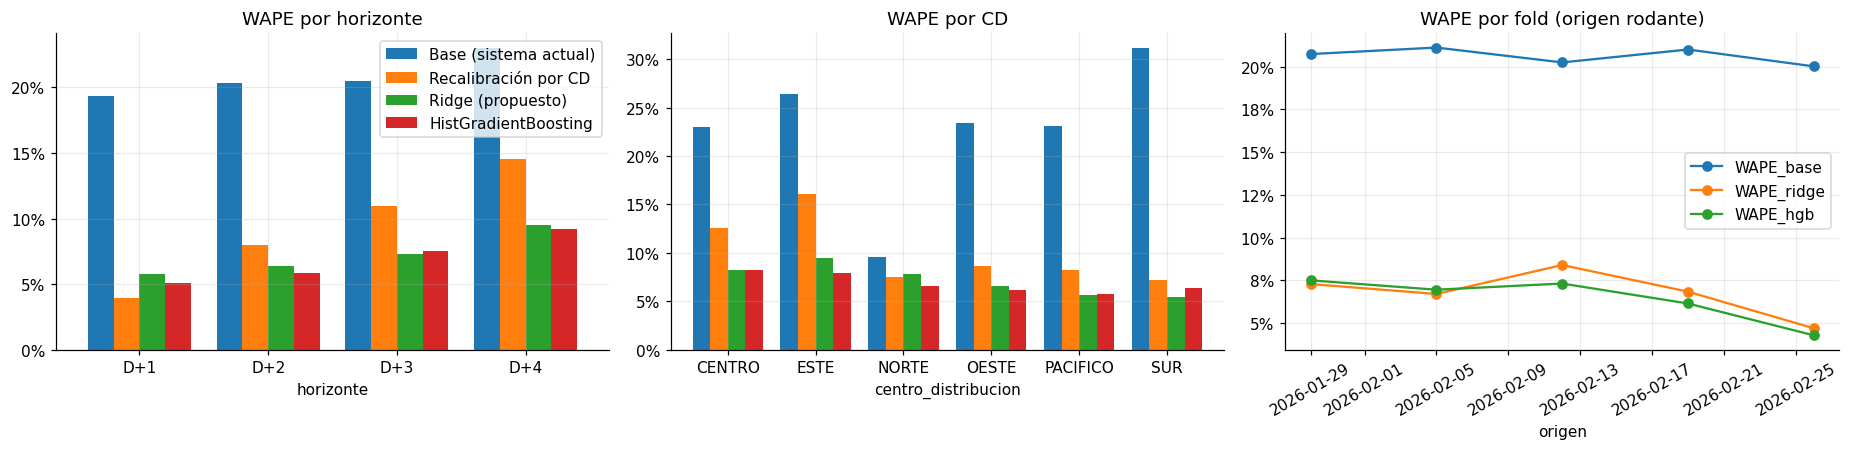

Coeficientes Ridge (features estandarizados; media ± std entre folds) — top 12:


,mean,std
feature,,
cat__centro_distribucion_CD_SUR,0.2539,0.0200
cat__centro_distribucion_CD_OESTE,-0.2501,0.0297
cat__centro_distribucion_CD_PACIFICO,-0.1688,0.0218
cat__centro_distribucion_CD_NORTE,0.1479,0.0308
num__fc_util,-0.1429,0.0097
num__lfc,-0.1374,0.0266
cat__centro_distribucion_CD_ESTE,0.0513,0.0142
num__fc_vs_rm7,0.0347,0.0034
cat__centro_distribucion_CD_CENTRO,-0.0341,0.0157


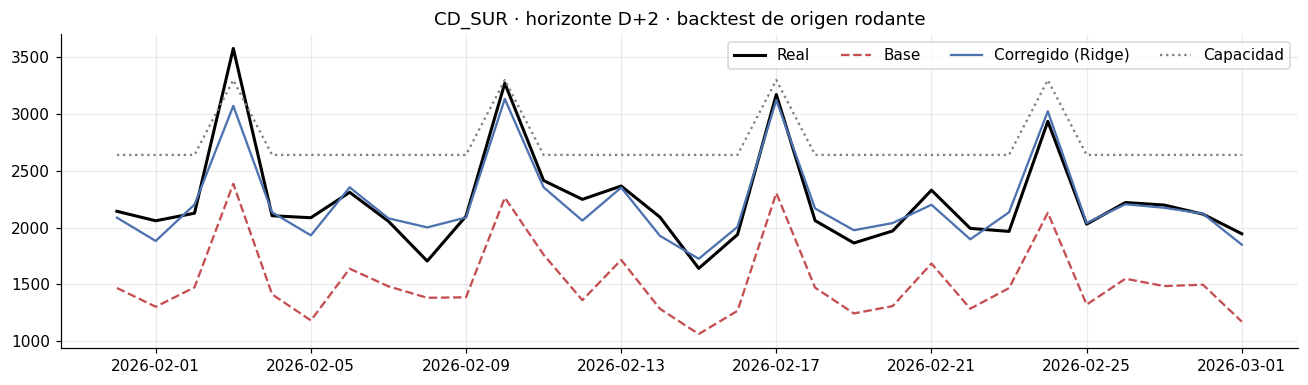

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
cmp_h.plot(kind="bar", ax=axes[0], rot=0, width=0.8); axes[0].set_title("WAPE por horizonte"); axes[0].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
cmp_cd.rename(index=lambda s: s.replace("CD_", "")).plot(kind="bar", ax=axes[1], rot=0, width=0.8, legend=False)
axes[1].set_title("WAPE por CD"); axes[1].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
fold_tbl.set_index("origen")[["WAPE_base", "WAPE_ridge", "WAPE_hgb"]].plot(ax=axes[2], marker="o", rot=30)
axes[2].set_title("WAPE por fold (origen rodante)"); axes[2].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
plt.tight_layout(); plt.show()

# Importancia: coeficientes Ridge promedio entre folds
cf = pd.concat(coefs).groupby("feature").coef.agg(["mean", "std"]).sort_values("mean", key=abs, ascending=False)
print("Coeficientes Ridge (features estandarizados; media ± std entre folds) — top 12:")
display(cf.head(12))

# Real vs base vs corregido para un CD ilustrativo (D+2)
cd_show = "CD_SUR"
s = bt[(bt.centro_distribucion == cd_show) & (bt.horizonte == "D+2")].sort_values("fecha_despacho")
plt.figure(figsize=(12, 3.6))
plt.plot(s.fecha_despacho, s.real, "k-", label="Real", lw=2)
plt.plot(s.fecha_despacho, s.pred_base, "--", color="#C44E52", label="Base")
plt.plot(s.fecha_despacho, s.pred_ridge, "-", color="#4C72B0", label="Corregido (Ridge)")
plt.plot(s.fecha_despacho, s.fecha_despacho.map(cap_w[cd_show]), ":", color="gray", label="Capacidad")
plt.title(f"{cd_show} · horizonte D+2 · backtest de origen rodante"); plt.legend(ncol=4); plt.tight_layout(); plt.show()

**Lectura de resultados (Tarea 3).**
- El modelo complementario **supera claramente al base**: WAPE global 20.7% → 7.2% (−13.5 pp, −65% relativo) sobre 708 pronósticos fuera de muestra; el IC95% por bootstrap de días no cruza 0 y Ridge mejora al base en los 5 folds, en los 4 horizontes y en los 6 CDs.
- **Origen de la mejora (ablación):** ~85% del salto (−11.5 pp de −13.5) viene de **des-sesgar por CD** con una simple razón histórica, algo que el diagnóstico de la Tarea 1 anticipaba. Los features de **calendario / picos / capacidad** (martes, fin de semana, `fc/capacidad`) aportan ~−0.7 pp adicionales y la estructura nivel+horizonte ~−1.4 pp. **Las rolling features y el error reciente no aportan mejora medible** (±0.03 pp, ruido): se mantienen por requerimiento del desafío y porque son baratas, pero con 60 días no hay evidencia de que añadan señal.
- **Hallazgo incómodo:** en **D+1** la recalibración simple por CD (WAPE 4.0%) supera al Ridge (5.8%); el Ridge gana desde D+2 y sobre todo en D+3/D+4, donde el pronóstico base es más ruidoso. Un modelo por horizonte (o una mezcla elegida por horizonte) es una mejora natural; **no se adopta aquí porque se decidiría mirando el mismo backtest** (riesgo de sobreajuste con 5 folds). Probé además interacciones `h × features` y distintos `alpha`: el WAPE se movió ±0.2 pp, dentro del ruido.
- **HGB vs Ridge:** HGB es marginalmente mejor (6.9% vs 7.2%, gana en 3 de 5 folds) pero la diferencia no justifica la pérdida de interpretabilidad con ~1.4k filas; se deja como *challenger* (intercambiable por LightGBM).
- **Cautela:** (i) la ventana de test es de ~32 días y no contiene festivos ni estacionalidad anual; (ii) la ganancia depende de que el sesgo por CD sea *estable* — si el modelo base se re-entrena o cambia de régimen, la corrección debe re-estimarse (re-entrenamiento semanal y monitoreo de Bias en §5); (iii) los datos parecen sintéticos con un sesgo multiplicativo por CD: en datos reales esperaría una mejora menor y más heterogénea.

---
## 4. Tarea 4 — Regla de resiliencia: Gate de historia mínima (Cold Start)

**Definición de "historia continua":** número de días *consecutivos* con demanda observada que terminan en el último día conocido (`as_of − 1`). Un hueco reinicia el conteo; una serie desactualizada (último dato anterior a `as_of − 1`) tiene historia 0. Así se evita habilitar el modelo con una serie "larga" pero rota o vieja.

**Política:**
- `historia ≥ 45 d` → **`TRAIN`**: el CD entra al entrenamiento y recibe pronóstico corregido.
- `historia < 45 d` → **`FALLBACK`**: se devuelve el pronóstico base (opcionalmente acotado a capacidad) y se registra el motivo. **Nunca lanza excepción**: entradas vacías, `None`, NaN o CDs desconocidos degradan a *fallback* con razón explícita.
- Si ningún CD califica, el entrenamiento se omite y todo el sistema opera en fallback.

In [20]:
@dataclass(frozen=True)
class GateDecision:
    """Resultado de evaluar la cobertura histórica de un CD."""
    centro_distribucion: str
    dias_continuos: int
    umbral: int
    estado: str          # "TRAIN" | "FALLBACK"
    razon: str


def continuous_history_days(series: pd.Series | None, as_of: pd.Timestamp) -> tuple[int, str]:
    """Días consecutivos con dato (>0, no NaN) que terminan en as_of−1. Devuelve (dias, motivo)."""
    if series is None or len(series) == 0:
        return 0, "sin_historia"
    s = pd.Series(series).dropna()
    s = s[(s.index < as_of) & (s > 0)]
    if s.empty:
        return 0, "sin_historia"
    last = s.index.max()
    if last < as_of - pd.Timedelta(days=1):
        return 0, f"serie_desactualizada(último_dato={last.date()})"
    days = pd.date_range(s.index.min(), last, freq="D")
    present = pd.Series(days.isin(s.index), index=days)
    gaps = present[~present]
    if gaps.empty:
        return int(len(days)), "continua"
    start = gaps.index.max() + pd.Timedelta(days=1)
    return int((last - start).days + 1), f"hueco_detectado(último_hueco={gaps.index.max().date()})"


def evaluate_history_gate(daily_actuals: pd.DataFrame | None, centers: Iterable[str], as_of: pd.Timestamp,
                          min_days: int = MIN_HISTORY_DAYS) -> dict[str, GateDecision]:
    """Evalúa el Gate por CD. Seguro ante cualquier entrada: jamás propaga excepciones."""
    decisions: dict[str, GateDecision] = {}
    for cd in centers:
        try:
            series = None if daily_actuals is None or cd not in getattr(daily_actuals, "columns", []) else daily_actuals[cd]
            n, why = continuous_history_days(series, pd.Timestamp(as_of))
            ok = n >= min_days
            decisions[cd] = GateDecision(cd, n, min_days, "TRAIN" if ok else "FALLBACK",
                                         "cobertura_suficiente" if ok else f"historia_insuficiente[{why}]")
        except Exception as exc:                      # noqa: BLE001 — contrato: nunca lanzar
            decisions[cd] = GateDecision(cd, 0, min_days, "FALLBACK", f"error_controlado[{type(exc).__name__}]")
    return decisions


def gated_forecast(fc_rows: pd.DataFrame, daily_actuals: pd.DataFrame | None, capacity: pd.DataFrame,
                   as_of: pd.Timestamp, min_days: int = MIN_HISTORY_DAYS,
                   cap_fallback: bool = False) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Pipeline completo con Gate. Entrena solo con CDs elegibles y aplica fallback al resto.

    Devuelve (pronósticos con columnas `fc_final`, `fuente`; tabla de decisiones del Gate).
    """
    centers = sorted(fc_rows.centro_distribucion.unique())
    dec = evaluate_history_gate(daily_actuals, centers, as_of, min_days)
    out = fc_rows.copy()
    out["fc_final"] = out["fc"].astype(float)
    out["fuente"] = "FALLBACK_BASE"
    eligible = [c for c, d in dec.items() if d.estado == "TRAIN"]
    if eligible:
        try:
            hist = daily_actuals.loc[daily_actuals.index < as_of, eligible]
            tr_rows = fc_rows[fc_rows.centro_distribucion.isin(eligible) & (fc_rows.fecha_despacho < as_of)].copy()
            tr_rows["real"] = [hist.at[d, c] if d in hist.index else np.nan
                               for d, c in zip(tr_rows.fecha_despacho, tr_rows.centro_distribucion)]
            tr_f = build_features(tr_rows.dropna(subset=["real"]), hist, capacity).dropna(subset=["y"])
            if len(tr_f) >= 40:
                mdl = make_ridge().fit(tr_f[FEATURES_NUM + FEATURES_CAT], tr_f.y)
                tgt = fc_rows[fc_rows.centro_distribucion.isin(eligible) & (fc_rows.fecha_emision >= as_of)].copy()
                tgt["real"] = np.nan
                # features de inferencia: solo historia < as_of (ya truncada en `hist`)
                tf = build_features(tgt, hist, capacity)
                yhat = np.clip(mdl.predict(tf[FEATURES_NUM + FEATURES_CAT]), np.log(RATIO_BOUNDS[0]), np.log(RATIO_BOUNDS[1]))
                key = list(zip(tf.centro_distribucion, tf.fecha_emision, tf.fecha_despacho))
                upd = dict(zip(key, tf.fc * np.exp(yhat)))
                idx = [(c, e, d) for c, e, d in zip(out.centro_distribucion, out.fecha_emision, out.fecha_despacho)]
                mask = pd.Series([k in upd for k in idx], index=out.index)
                out.loc[mask, "fc_final"] = [upd[k] for k, m in zip(idx, mask) if m]
                out.loc[mask, "fuente"] = "MODELO_CORREGIDO"
            else:
                for c in eligible:
                    dec[c] = GateDecision(c, dec[c].dias_continuos, min_days, "FALLBACK", "filas_de_entrenamiento_insuficientes")
        except Exception as exc:                      # noqa: BLE001 — resguardo final
            for c in eligible:
                dec[c] = GateDecision(c, dec[c].dias_continuos, min_days, "FALLBACK", f"error_entrenamiento[{type(exc).__name__}]")
            out["fc_final"] = out["fc"].astype(float); out["fuente"] = "FALLBACK_BASE"
    if cap_fallback:
        c_map = capacity.stack().rename("cap").reset_index().rename(columns={"fecha": "fecha_despacho"})
        out = out.merge(c_map, on=["fecha_despacho", "centro_distribucion"], how="left")
        out["fc_final"] = np.where(out.fuente == "FALLBACK_BASE", np.minimum(out.fc_final, out.cap.fillna(np.inf)), out.fc_final)
        out = out.drop(columns="cap")
    table = pd.DataFrame([d.__dict__ for d in dec.values()]).set_index("centro_distribucion")
    return out, table

### Demostración: escenarios de Cold Start (sin excepciones)
Fecha de corte `as_of = 2026-02-20`. Se simulan situaciones adversas sobre la historia real: un CD con 20 días (nuevo), otro con **44 días** (justo bajo el umbral), uno con **exactamente 45**, uno con un hueco reciente y uno sin ningún dato.

In [21]:
as_of = pd.Timestamp("2026-02-20")
hist = daily.copy()
start = as_of - pd.Timedelta(days=1)
hist.loc[hist.index < start - pd.Timedelta(days=19), "CD_OESTE"] = np.nan       # 20 días de historia
hist.loc[hist.index < start - pd.Timedelta(days=43), "CD_ESTE"] = np.nan        # 44 días
hist.loc[hist.index < start - pd.Timedelta(days=44), "CD_PACIFICO"] = np.nan    # 45 días exactos
hist.loc[(hist.index >= "2026-02-10") & (hist.index <= "2026-02-12"), "CD_CENTRO"] = np.nan   # hueco reciente
hist["CD_SUR"] = np.nan                                                          # sin datos
# CD_NORTE: historia completa (50 días hasta as_of−1)

print("Prueba de contrato: entradas patológicas no lanzan excepción")
for label, d in {"None": None, "DataFrame vacío": pd.DataFrame(), "Todo NaN": hist * np.nan}.items():
    r = evaluate_history_gate(d, CDS, as_of)
    print(f"  {label:18s} → {sorted({x.estado for x in r.values()})}")
print("  CD desconocido    →", evaluate_history_gate(hist, ["CD_FANTASMA"], as_of)["CD_FANTASMA"].razon)

gated, gate_tbl = gated_forecast(fc, hist, cap_w, as_of)
display(gate_tbl)
print(gated[gated.fecha_emision >= as_of].groupby(["centro_distribucion", "fuente"]).size().unstack(fill_value=0))
assert np.isfinite(gated.fc_final).all() and (gated.fc_final > 0).all()

Prueba de contrato: entradas patológicas no lanzan excepción
  None               → ['FALLBACK']
  DataFrame vacío    → ['FALLBACK']
  Todo NaN           → ['FALLBACK']
  CD desconocido    → historia_insuficiente[sin_historia]


,dias_continuos,umbral,estado,razon
centro_distribucion,,,,
CD_CENTRO,7,45,FALLBACK,historia_insuficiente[hueco_detectado(último_h...
CD_ESTE,44,45,FALLBACK,historia_insuficiente[continua]
CD_NORTE,50,45,TRAIN,cobertura_suficiente
CD_OESTE,20,45,FALLBACK,historia_insuficiente[continua]
CD_PACIFICO,45,45,TRAIN,cobertura_suficiente
CD_SUR,0,45,FALLBACK,historia_insuficiente[sin_historia]


fuente               FALLBACK_BASE  MODELO_CORREGIDO
centro_distribucion                                 
CD_CENTRO                       30                 0
CD_ESTE                         30                 0
CD_NORTE                         0                30
CD_OESTE                        30                 0
CD_PACIFICO                      0                30
CD_SUR                          30                 0


### Argumentación cuantitativa: ¿qué pasa si se mueve el umbral?
Se evalúa en el mismo backtest (reentrenando **cada día** con la historia disponible) tres cosas: (1) el error que se obtiene según el umbral aplicado, (2) el error de estimación del sesgo por CD en función de los días de historia y (3) la cobertura por día de semana.

In [22]:
def daily_origin_backtest(f: pd.DataFrame, first_origin: int = 8) -> pd.DataFrame:
    """Reentrena cada día (E0 = 8..58) con todo lo conocido y predice las emisiones de ese día."""
    t0 = daily.index.min()
    emis = (f.fecha_emision - t0).dt.days
    res = []
    for e0 in range(first_origin, int(emis.max()) + 1):
        tr = f[f.fecha_despacho < t0 + pd.Timedelta(days=e0)]
        te = f[emis == e0].copy()
        if len(tr) < 25 or te.empty:
            continue
        mdl = make_ridge().fit(tr[FEATURES_NUM + FEATURES_CAT], tr.y)
        te["pred_model"] = te.fc * np.exp(np.clip(mdl.predict(te[FEATURES_NUM + FEATURES_CAT]), *np.log(RATIO_BOUNDS)))
        te["hist_days"] = e0
        res.append(te)
    return pd.concat(res, ignore_index=True)


dbt = daily_origin_backtest(feat)
sweep = []
for T in [7, 14, 21, 28, 35, 45, 52]:
    pred = np.where(dbt.hist_days >= T, dbt.pred_model, dbt.fc)
    t = dbt.assign(pred=pred)
    act = dbt.hist_days >= T
    m = error_metrics(t, None, pred="pred").iloc[0]
    sweep.append({"umbral_T": T, "%días_en_fallback": 1 - act.mean(), "WAPE_global": m.WAPE, "Bias_global": m.Bias})
sweep = pd.DataFrame(sweep).set_index("umbral_T")
base_all = error_metrics(dbt, None, pred="fc").iloc[0]
sweep["ganancia_vs_base_pp"] = (base_all.WAPE - sweep.WAPE_global) * 100
sweep["costo_de_esperar_vs_T7_pp"] = (sweep.WAPE_global - sweep.WAPE_global.iloc[0]) * 100
print(f"WAPE base (sin modelo) en la misma ventana: {base_all.WAPE:.2%};  modelo siempre activo desde día 8: "
      f"{error_metrics(dbt, None, pred='pred_model').WAPE.iloc[0]:.2%}")
display(sweep)

# (2) Precisión de la estimación del sesgo vs días de historia  (D+1, independiente por día)
d1 = fc[fc.h == 1].assign(lr=lambda d: np.log(d.real / d.fc))
sig = d1.groupby("centro_distribucion").lr.std()
mu = d1.groupby("centro_distribucion").lr.mean()
rows = []
for n in [7, 14, 21, 28, 35, 45, 60]:
    rows.append({"días_historia": n, "obs_por_día_semana": n // 7,
                 **{c.replace("CD_", ""): sig[c] / math.sqrt(n) for c in CDS}})
se_tbl = pd.DataFrame(rows).set_index("días_historia")
print("\nError estándar de la estimación del sesgo log (σ/√n) por CD — comparar con |sesgo real|:")
display(se_tbl)
need = pd.DataFrame({"|sesgo_log|": mu.abs(), "σ_diaria": sig,
                     "días_mín_para_detectar (z≥3)": np.ceil((3 * sig / mu.abs()) ** 2)}).sort_values("|sesgo_log|")
display(need)

WAPE base (sin modelo) en la misma ventana: 20.82%;  modelo siempre activo desde día 8: 7.64%


,%días_en_fallback,WAPE_global,Bias_global,ganancia_vs_base_pp,costo_de_esperar_vs_T7_pp
umbral_T,,,,,
7,0.0000,0.0764,0.0011,13.1862,0.0000
14,0.1212,0.0900,0.0113,11.8222,1.3640
21,0.2626,0.1100,0.0204,9.8184,3.3678
28,0.4040,0.1273,0.0314,8.0877,5.0985
35,0.5455,0.1464,0.0404,6.1773,7.0089
45,0.7475,0.1746,0.0498,3.3616,9.8246
52,0.8889,0.1919,0.0570,1.6358,11.5504



Error estándar de la estimación del sesgo log (σ/√n) por CD — comparar con |sesgo real|:


,obs_por_día_semana,CENTRO,ESTE,NORTE,OESTE,PACIFICO,SUR
días_historia,,,,,,,
7,1,0.0260,0.0266,0.0168,0.0161,0.0157,0.0140
14,2,0.0184,0.0188,0.0118,0.0114,0.0111,0.0099
21,3,0.0150,0.0154,0.0097,0.0093,0.0091,0.0081
28,4,0.0130,0.0133,0.0084,0.0080,0.0079,0.0070
35,5,0.0116,0.0119,0.0075,0.0072,0.0070,0.0062
45,6,0.0102,0.0105,0.0066,0.0063,0.0062,0.0055
60,8,0.0089,0.0091,0.0057,0.0055,0.0054,0.0048


,|sesgo_log|,σ_diaria,días_mín_para_detectar (z≥3)
centro_distribucion,,,
CD_NORTE,0.0903,0.0443,3.0000
CD_CENTRO,0.1775,0.0687,2.0000
CD_PACIFICO,0.1833,0.0417,1.0000
CD_OESTE,0.2273,0.0425,1.0000
CD_ESTE,0.2866,0.0704,1.0000
CD_SUR,0.3817,0.0369,1.0000


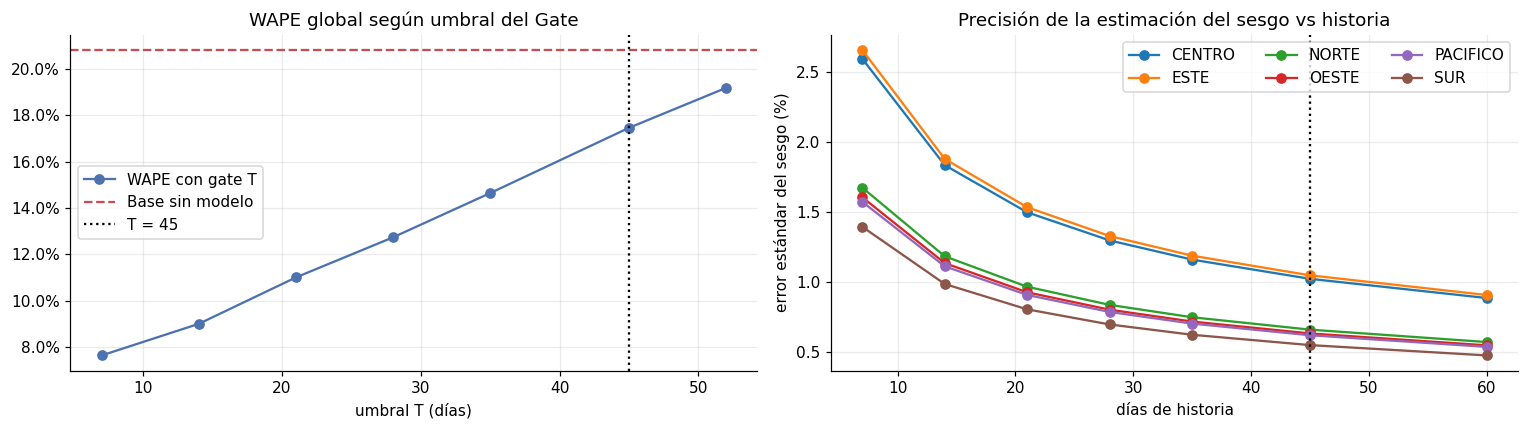

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(sweep.index, sweep.WAPE_global, "o-", color="#4C72B0", label="WAPE con gate T")
axes[0].axhline(base_all.WAPE, color="#C44E52", ls="--", label="Base sin modelo")
axes[0].axvline(MIN_HISTORY_DAYS, color="k", ls=":", label="T = 45")
axes[0].set_xlabel("umbral T (días)"); axes[0].set_title("WAPE global según umbral del Gate"); axes[0].legend()
axes[0].yaxis.set_major_formatter(lambda v, _: f"{v:.1%}")
for c in CDS:
    axes[1].plot(se_tbl.index, se_tbl[c.replace("CD_", "")] * 100, marker="o", label=c.replace("CD_", ""))
axes[1].axvline(MIN_HISTORY_DAYS, color="k", ls=":")
axes[1].set_xlabel("días de historia"); axes[1].set_ylabel("error estándar del sesgo (%)"); axes[1].set_title("Precisión de la estimación del sesgo vs historia")
axes[1].legend(ncol=3); plt.tight_layout(); plt.show()

### Ventajas y riesgos de ajustar el umbral (45 d)

| | **Bajar el umbral** (p. ej. 14–28 d) | **Subir el umbral** (p. ej. 60–90 d) |
|---|---|---|
| **Ventajas** | Menos tiempo en fallback para CDs nuevos: con T=14 el modelo está activo ~88% de los días evaluados y el WAPE global es ~9% vs ~17% con T=45 (columna `costo_de_esperar_vs_T7_pp`). | Estimaciones más estables: ≥ 6–8 observaciones por día de semana, más folds de validación *antes* de activar y menor riesgo de sobre-corregir un régimen transitorio (apertura, promoción). |
| **Riesgos** | Con 14 días hay solo 2 observaciones por día de semana: `es_martes`, `lag7` y el rolling 14d no son estimables, y el error estándar del sesgo (σ/√n) es √(45/14) ≈ 1.8× mayor que a 45 días. Riesgo de **sobre-corregir** un sesgo que sea ruido o transitorio, con impacto directo en flota. | Costo de oportunidad medible: con T=45 los CDs pasan ~75% de la ventana evaluada sin corrección (WAPE ≈ 17% vs ≈ 8% con T=7) → semanas de flete de emergencia evitable en CDs nuevos. |

**Lectura cuantitativa en estos datos:**
- **En estos datos no hay evidencia de riesgo al bajar el umbral**: el WAPE mejora monótonamente al reducir T (el modelo ya vence al base desde el día 8 en la ventana evaluada) y el sesgo por CD (9–38% en log) es mucho mayor que su error estándar de estimación (0.5–2.7% entre 7 y 60 días): bastan 1–3 días de historia para detectarlo con z ≥ 3. Es decir, **el umbral de 45 d es conservador y tiene un costo medible** (tabla de arriba).
- **Lo que los datos no pueden mostrar** (y es lo que justifica un umbral prudente): un sesgo estable en 60 días no garantiza estabilidad en producción: estacionalidad mensual/anual, festivos, apertura o ramp-up de un CD, o cambios en el modelo base. Con ≥ 45 días se tienen ≥ 6 observaciones por día de semana y al menos ~4 folds de validación de origen rodante *antes* de confiar en el modelo.
- **Recomendación:** mantener 45 d como umbral de *activación completa* y añadir un **modo intermedio** (14 ≤ historia < 45): solo recalibración de nivel por CD con *shrinkage* hacia 1 (p. ej. 50%), sin features de calendario — captura la mayor parte del beneficio con riesgo acotado. Calibrar T con el costo asimétrico real (flete de emergencia vs flota ociosa) y revisarlo trimestralmente repitiendo este análisis.
- El Gate debe operar **por CD** y de forma **continua**: un CD que pierde datos (hueco) vuelve a fallback automáticamente, y todo cambio de estado se registra y alerta.

---
## 5. Tarea 5 — Arquitectura en AWS

```mermaid
flowchart LR
  subgraph SRC[Fuentes]
    OMS[Plataforma B2B / OMS<br/>pedidos y plan de entrega]
    FCS[Pronóstico base<br/>D+1..D+4]
    CAPS[Capacidad logística<br/>por CD]
  end
  subgraph ING[Ingesta]
    KDF[Kinesis Data Firehose<br/>eventos de pedido]
    S3RAW[(S3 raw)]
  end
  subgraph BATCH[Batch / Re-entrenamiento semanal]
    EB[EventBridge<br/>cron diario + semanal]
    SF[Step Functions]
    GLUE[Glue / Athena<br/>features rolling]
    GATE{Lambda<br/>Gate de 45 días}
    SMT[SageMaker Training<br/>Ridge / HGB]
    EVAL[Backtest origen rodante<br/>+ comparación vs base]
    REG[SageMaker Model Registry<br/>aprobación condicionada]
  end
  subgraph SERVE[Inferencia]
    APIGW[API Gateway]
    LAM[Lambda / ECS Fargate<br/>servicio de recomendación]
    CACHE[ElastiCache<br/>features y utilización]
  end
  subgraph STORE[Persistencia]
    S3C[(S3 curated + artefactos)]
    DDB[(DynamoDB<br/>estado del Gate, versión de modelo,<br/>pedidos comprometidos por CD-día)]
    ATH[(Athena / S3<br/>historial de métricas WAPE/Bias)]
  end
  subgraph OBS[Monitoreo]
    CW[CloudWatch<br/>métricas + alarmas]
    SNS[SNS / Slack]
  end
  APP[App backend / web B2B]
  OMS --> KDF --> S3RAW
  FCS --> S3RAW
  CAPS --> S3RAW
  EB --> SF --> GLUE --> GATE
  S3RAW --> GLUE
  GATE -- CDs elegibles --> SMT --> EVAL --> REG
  GATE -- CDs en fallback --> DDB
  REG --> S3C
  EVAL --> ATH
  GLUE --> S3C
  APP -->|POST /recomendar-fecha| APIGW --> LAM
  LAM --> CACHE
  LAM -->|lee modelo + estado| S3C
  LAM -->|lee Gate y carga comprometida| DDB
  LAM -->|registra recomendación| ATH
  LAM --> APP
  ATH --> CW --> SNS
  EVAL --> CW
```

### Componentes e interacciones

| Capa | Componente | Responsabilidad | Justificación de diseño |
|---|---|---|---|
| **Ingesta** | Kinesis Firehose → S3 raw | Aterriza eventos de pedido y los CSV de pronóstico/capacidad, particionados por fecha y CD. | Desacopla la plataforma transaccional del analítico; costo bajo, esquema inmutable y reproducible. |
| **Batch / re-entrenamiento** | EventBridge → Step Functions | Orquesta el pipeline diario (features + gate + inferencia por lote) y semanal (re-entrenamiento + backtest). | Orquestación con reintentos, trazabilidad y bifurcación explícita por el Gate. |
| | Glue / Athena | Construye features rolling y tablas curadas leakage-safe (corte `as_of`). | SQL/Spark serverless; sin clústeres que operar para 6 CDs, escala si crecen. |
| | **Lambda "Gate de historia"** | Calcula días continuos por CD; decide `TRAIN` / `FALLBACK` y escribe el estado en DynamoDB. | Lógica pequeña, determinista y auditable; es la única puerta de entrada al entrenamiento. |
| | SageMaker Training + Model Registry | Entrena el modelo de corrección con CDs elegibles; el modelo solo se promueve si **WAPE_backtest(modelo) < WAPE(base)** y no empeora ningún CD > X pp. | *Champion/challenger* con aprobación condicionada: evita promover regresiones. |
| **Inferencia** | API Gateway + Lambda (o Fargate) | Endpoint `POST /recomendar-fecha`: recibe CD y pedido, devuelve fechas candidatas ordenadas por utilización proyectada con el pronóstico corregido. | Un Ridge pesa KB y se evalúa en ms → Lambda es suficiente (SageMaker endpoint solo si migra a un modelo pesado). Latencia p95 objetivo < 200 ms. |
| | ElastiCache | Cache de features y de la carga comprometida por CD-día. | Evita golpear Athena/S3 en el camino crítico. |
| **Persistencia** | S3 (curated + artefactos) | Datos de entrenamiento, modelos versionados, predicciones batch. | Fuente de verdad auditable. |
| | DynamoDB | Estado operativo de baja latencia: estado del Gate por CD, versión de modelo activa, carga comprometida. | Lecturas de ms en la ruta de recomendación; TTL y PITR. |
| | Athena sobre S3 | Historial de métricas (WAPE, Bias por CD/horizonte), recomendaciones emitidas y aceptación. | Análisis histórico y *drift* sin servidor dedicado. |
| **Observabilidad** | CloudWatch + SNS | Alarmas: Bias móvil 7d fuera de ±X%, WAPE > base, cambio de estado del Gate, datos faltantes/desactualizados. | Cierra el ciclo: el drift de sesgo dispara re-entrenamiento o *fallback* automático. |

**Flujo de punta a punta:** (1) los pedidos y pronósticos aterrizan en S3; (2) cada madrugada Step Functions corre features + Gate; (3) CDs elegibles usan el modelo vigente del Registry, el resto queda en *fallback* seguro con el pronóstico base; (4) la app consulta el endpoint, que combina el pronóstico corregido con la carga ya comprometida y devuelve la fecha de menor utilización; (5) cada semana se re-entrena, se compara en backtest contra el base y solo se promueve si mejora; (6) las métricas se persisten y alertan ante deriva.

**Decisiones y trade-offs:** *serverless-first* (el volumen es pequeño: 6 CDs × 4 horizontes); *fallback antes que fallo* (el endpoint siempre responde, aun sin modelo); *versionado + reproducibilidad* (cada recomendación guarda `model_version`, `gate_state` y `as_of`); costo estimado bajo (Lambda + S3 + DynamoDB on-demand + 1 job semanal).

---
## 6. Impacto de negocio: flota, fletes de emergencia y nivel de servicio

**Modelo simple de costo (supuestos explícitos, parametrizables):** la flota se contrata en función del pronóstico: `contratado = min(pronóstico × (1 + colchón), capacidad)`. Lo que excede lo contratado se cubre con **flete de emergencia** (más caro) y lo contratado no usado es **capacidad ociosa**.
- Costo unitario flota planificada = 1.00 (se paga lo contratado, se use o no); flete de emergencia = **1.80×** (supuesto; ajustar con tarifas reales).
- **Nivel de servicio (fill rate propio)** = unidades cubiertas por la flota contratada / unidades reales.
- Se evalúa sobre las filas del backtest de origen rodante (out-of-sample), mismo conjunto para base y corregido.

In [24]:
COST_PLAN, COST_EMERGENCY = 1.00, 1.80


def fleet_impact(df: pd.DataFrame, pred: str, buffer: float = 0.0) -> pd.Series:
    idx = pd.MultiIndex.from_arrays([df.fecha_despacho, df.centro_distribucion])
    cap_row = pd.Series(cap_w.stack().reindex(idx).to_numpy(), index=df.index)
    booked = np.minimum(df[pred] * (1 + buffer), cap_row)
    emerg = np.maximum(df.real - booked, 0.0)
    idle = np.maximum(booked - df.real, 0.0)
    return pd.Series({
        "unid_emergencia": emerg.sum(), "unid_ociosas": idle.sum(),
        "%_flete_emergencia": emerg.sum() / df.real.sum(),
        "%_capacidad_ociosa": idle.sum() / booked.sum(),
        "fill_rate": 1 - emerg.sum() / df.real.sum(),
        "costo_total_idx": COST_PLAN * booked.sum() + COST_EMERGENCY * emerg.sum()})


rows = {}
for buf in [0.0, 0.05, 0.10]:
    for col, lbl in [("pred_base", "Base"), ("pred_ridge", "Corregido")]:
        rows[(f"colchón {buf:.0%}", lbl)] = fleet_impact(bt, col, buf)
impact = pd.DataFrame(rows).T
display(impact)

print("\nReducción relativa Base → Corregido:")
red = []
for buf in ["colchón 0%", "colchón 5%", "colchón 10%"]:
    b, c = impact.loc[(buf, "Base")], impact.loc[(buf, "Corregido")]
    red.append({"escenario": buf,
                "Δ unid. emergencia": c.unid_emergencia / b.unid_emergencia - 1,
                "Δ unid. ociosas": c.unid_ociosas / b.unid_ociosas - 1,
                "Δ costo total": c.costo_total_idx / b.costo_total_idx - 1,
                "Δ fill rate (pp)": (c.fill_rate - b.fill_rate) * 100})
display(pd.DataFrame(red).set_index("escenario"))

# Por CD (colchón 5%)
per_cd = pd.DataFrame({cd: {"emergencia_base": fleet_impact(g, "pred_base", 0.05).unid_emergencia,
                            "emergencia_corr": fleet_impact(g, "pred_ridge", 0.05).unid_emergencia,
                            "ociosas_base": fleet_impact(g, "pred_base", 0.05).unid_ociosas,
                            "ociosas_corr": fleet_impact(g, "pred_ridge", 0.05).unid_ociosas}
                       for cd, g in bt.groupby("centro_distribucion")}).T
display(per_cd.round(0))

unid_emergencia  unid_ociosas  %_flete_emergencia  %_capacidad_ociosa  fill_rate  costo_total_idx
colchón 0%  Base          143,892.9900   47,355.2500              0.1381              0.0501     0.8619   1,204,731.6520
            Corregido      42,904.8006   32,017.5364              0.0412              0.0310     0.9588   1,108,603.3869
colchón 5%  Base          118,869.0625   58,001.9395              0.1140              0.0591     0.8860   1,195,359.1995
            Corregido      22,709.9805   62,693.1636              0.0218              0.0579     0.9782   1,123,123.1580
colchón 10% Base           98,040.9790   69,980.2160              0.0941              0.0690     0.9059   1,190,675.0092
            Corregido      12,575.0247  100,747.2769              0.0121              0.0891     0.9879   1,153,069.3067


Reducción relativa Base → Corregido:


,Δ unid. emergencia,Δ unid. ociosas,Δ costo total,Δ fill rate (pp)
escenario,,,,
colchón 0%,-0.7018,-0.3239,-0.0798,9.6893
colchón 5%,-0.8089,0.0809,-0.0604,9.2260
colchón 10%,-0.8717,0.4397,-0.0316,8.2000


,emergencia_base,emergencia_corr,ociosas_base,ociosas_corr
CD_CENTRO,"2,421.0000","5,528.0000","26,829.0000","10,312.0000"
CD_ESTE,"21,655.0000","3,574.0000",507.0000,"5,951.0000"
CD_NORTE,"21,072.0000","7,847.0000","6,438.0000","24,492.0000"
CD_OESTE,317.0000,"1,147.0000","11,310.0000","3,353.0000"
CD_PACIFICO,133.0000,"1,047.0000","12,896.0000","3,957.0000"
CD_SUR,"73,271.0000","3,567.0000",22.0000,"14,629.0000"


In [25]:
sens = {}
for mult in [1.5, 1.8, 2.5, 3.0]:
    COST_EMERGENCY = mult
    b, c = fleet_impact(bt, "pred_base", 0.05), fleet_impact(bt, "pred_ridge", 0.05)
    sens[f"flete emergencia {mult:.1f}×"] = {"Δ costo total (colchón 5%)": c.costo_total_idx / b.costo_total_idx - 1}
COST_EMERGENCY = 1.80
print("Sensibilidad al supuesto de tarifa del flete de emergencia:")
display(pd.DataFrame(sens).T)

Sensibilidad al supuesto de tarifa del flete de emergencia:


,Δ costo total (colchón 5%)
flete emergencia 1.5×,-0.0374
flete emergencia 1.8×,-0.0604
flete emergencia 2.5×,-0.1091
flete emergencia 3.0×,-0.1402


**Lectura del impacto (supuestos arriba, out-of-sample):**
- **Fletes de emergencia: −70% a −87%** de unidades según el colchón; el *fill rate* de la flota planificada sube ~8–10 pp (p. ej. 88.6% → 97.8% con colchón 5%).
- **Es un trade-off, no una mejora gratis:** al quitar el sesgo de sobreestimación en CD_CENTRO/OESTE/PACIFICO desaparece un "colchón involuntario": en CD_CENTRO los fletes de emergencia **suben** (≈2.4k → 5.5k unidades), y en CD_NORTE la capacidad ociosa sube porque el modelo base subestimaba y contrataba menos. Con colchón de 10% la capacidad ociosa total aumenta +44%: **el modelo corregido necesita menos colchón que el base** (al estar des-sesgado, un colchón fijo de 10% sobre-contrata).
- **Costo total (índice): −8% / −6% / −3%** con colchón 0/5/10%. El ahorro es positivo en todas las tarifas de flete de emergencia evaluadas y crece con el sobrecosto del flete.
- La magnitud depende de supuestos de tarifa y del proceso de contratación; es un orden de magnitud para priorizar, no un P&L.

### KPIs propuestos para seguimiento

| Dimensión | KPI | Meta / uso |
|---|---|---|
| Precisión | WAPE y Bias por CD × horizonte (rolling 7d / 28d) | Bias en ±5%; WAPE ≤ base en todos los CDs |
| Costo | **% de unidades en flete de emergencia**; costo logístico por unidad | ↓ vs línea base; mide el beneficio directo |
| Flota | % capacidad contratada ociosa | ↓ sin elevar emergencia (frontera de Pareto vía colchón) |
| Servicio | Fill rate / OTIF por CD | ≥ nivel actual (guardrail) |
| Aplanamiento | PAR semanal, % CD-días con utilización > 90%, share martes | Medir A/B de la estrategia de fecha dinámica |
| Plan | Adhesión al plan (% en fecha), Bias de volumen del plan | Detectar clientes crónicos y corregir volumen |
| Resiliencia | % CD-días en fallback, tiempo medio a salir de fallback | Salud del Gate |

---
## 7. Alcance y limitaciones

**Hecho en este notebook:** diagnóstico (Tarea 1), análisis del plan y estrategia (Tarea 2), modelo con rolling-origin y ablación (Tarea 3), Gate con pruebas y argumentación cuantitativa (Tarea 4), arquitectura AWS en Mermaid (Tarea 5) e impacto de negocio con supuestos explícitos.

**Limitaciones:**
- **60 días** de historia: no hay estacionalidad mensual/anual, festivos ni promociones; el backtest evalúa ~4 semanas. Las mejoras podrían ser menores en producción.
- El dataset parece **sintético** (sesgo multiplicativo estable por CD); la corrección depende de esa estabilidad.
- El impacto económico usa **supuestos de tarifa** (flete de emergencia 1.8×) y no reemplaza datos de costo reales; la simulación de aplanamiento no modela elasticidad ni el costo del incentivo.
- El dataset de plan cubre 90 clientes (~15% del volumen de los CDs): sus conclusiones son indicativas, no extrapolables sin muestreo adicional.
- El pronóstico se corrige a nivel CD-día; no hay corrección por canal ni por cliente.